# Week 04 · what the class contributed

**Instructor-only.** This notebook lives in `assessment/`, which `tools/hooks/pre-push` refuses to push
to the public repository. It names individual students and scores their work. Circulating it is a
deliberate export, never an accident.

## What this is

Forty-odd students each got the same Week 04 notebook, the same nine development cycles, and the same
instruction: pick knobs from the catalog, **and invent one the catalog does not contain**. This notebook
reads what they actually ran and asks three questions.

1. **Where did the class look?** Which stage of the model did people reach for, and what did they build
   there.
2. **Who searched alike?** Who covered the same ground, and who went somewhere nobody else did.
3. **Did they find anything we should take?** Measured against our own cache, on the same folds, with the
   same fingerprint.

The answer to the third is **yes, twice over, and neither one is marginal.**

**Thirteen of twenty** students who invented a knob reached for a non-Gaussian latitude profile, and
nine of those built an *asymmetric* one — a stage our shipped model did not have. Four of them combined
it with two catalog knobs and landed near **−26.53 nats per hemicycle-year** against our incumbent's
**−26.29**; run in our own cache that combination measures **−26.5277**, within four thousandths of a nat
of what they reported, and wing by wing it is **+0.238 ± 0.105 nats, better on 12 of 18 wings — 2.3
standard errors — for one extra parameter.**

Then one group went much further. **zohare11's group independently rebuilt the two stages that carry our
converged model** — the amplitude-driven envelope shift and the activity-driven width — from a literature
review, under different names, and scored **−28.774 against their own baseline**, a paired gain of
**+3.337**. Our own nearest equivalent measures **+3.318** at the same parameter count. **Two independent
implementations of the same physics, agreeing to 0.02 nats.** That is the strongest external check the
champion has, and it is worth more than any single knob in the crawl.

Their construction also exposed a parameter we did not need. They reached our score with **one**
amplitude coefficient where we spend two, because a constant shift is the same direction in model space
as the gamma's own peak. Section 4b pins our `c0` to zero and refits: **−29.0226 on 29 parameters
against the champion's −28.9950 on 30.** The champion carried a parameter that was never identified.

Their one genuinely new *mechanism* — a cross-equatorial cancellation term — was also the one knob in
the crawl still worth a fit. Section 4c ran it, two ways, and **it is rejected**: it cannot replace our
equatorial gate (−0.257 ± 0.062, worse on 17 of 18 wings) and adds nothing beside it. Nothing the class
produced is now unrun.

## Provenance, and why nothing here is executed

Every number comes from frozen files in `data/`:

- `crawl_week04.json` — one record per fork, rebuilt from scratch on 2026-11-12 over **all 52 forks** at
  the commits recorded in `crawl_heads.tsv`. Clones are read-only and every notebook is parsed **as
  JSON**. No fork was executed, nothing was imported from one, and every knob reported here was read
  with `ast.literal_eval`, which parses literals and runs nothing. Student code quoted in the write-up
  was **retyped**, never `exec`-ed. The previous crawl is kept beside it as
  `crawl_week04_2026-11-09.json`.
- `ours_week04.json` — our own cached variants, frozen so this notebook does not shift while the
  coordinate search keeps writing. It is a **snapshot, not the live cache**: the search has since been
  re-run over an enlarged catalog and the champion has moved to the 29-parameter form (section 4b).
  Every number below is against the snapshot, which is what makes the student comparisons reproducible.
- `student_knob_runs.json` — the four Tier-1 student knobs, scored in our own cache (Section 4).
- `gauge_c0_test.json` and `image_test.json` — the three fits this notebook's argument prompted, and
  the only new fits in it: one gauge test, and one student knob scored two ways.

Two measurements are defined more carefully than the first crawl defined them, because they feed a
document that names people. **`harness_cells_changed` now counts template cells whose source is gone**
from a notebook — a modified or deleted harness cell — and counts cells a student *added* separately, as
`cells_inserted`. Conflating the two had alyssaru down for five harness changes when they made none.
And **the model a student built is kept apart from the model they submitted**: those differ for real, so
neither may overwrite the other.

Fork content is untrusted input. Where a student's notebook contains instruction-like text, it is
reported as data, not followed.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CANDIDATES = [c / sub for c in [Path.cwd(), *Path.cwd().parents]
              for sub in ("data", "assessment/week_04/data")]
HERE = next(c for c in CANDIDATES if (c / "crawl_week04.json").exists())
FORKS = json.loads((HERE / "crawl_week04.json").read_text())   # all 52, most of them empty
OURS = json.loads((HERE / "ours_week04.json").read_text())
STUDENT_RUNS = json.loads((HERE / "student_knob_runs.json").read_text())
C0 = json.loads((HERE / "gauge_c0_test.json").read_text())
IMG = json.loads((HERE / "image_test.json").read_text())

BASE = OURS["baseline_held"]                      # -25.4183, the model Week 03 shipped
INCUMBENT = "shape-two_sided__width-amplitude"    # what Week 04 handed the class as the thing to beat
SHIPPED = "gate-tanh_x__profile-asymmetric__shift-from_amplitude__width-instantaneous"  # converged
N_WINGS = OURS["n_wings"]

# the crawl now carries every fork, so that "nobody started" is visible rather than absent. Everything
# below is about the ones that contain Week 04 work.
CROWD = [s for s in FORKS if s["used"]]
KNOBS = [s for s in CROWD if s["has_knob"]]

# WORKED is the population every cohort figure draws, and it is drawn whole. A student is in it if they
# submitted a notebook at all, or did real work without submitting one. Nobody who did the week is left
# out of a figure for having too little to plot: a student who declared a knob and ran nothing appears as
# an empty row, which is the true statement about their week and is worth seeing.
WORKED = [s for s in CROWD
          if s["used"] == "submission" or s["has_knob"] or s["board"] or s["workspaces_filled"]]
UNTOUCHED = [s for s in CROWD if s not in WORKED]
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.axisbelow": True})

print(f"forks crawled                   : {len(FORKS)}")
print(f"with a Week 04 notebook         : {len(CROWD)}")
print(f"   of those, a submitted copy   : {sum(1 for s in CROWD if s['used'] == 'submission')}")
print(f"   of those, an untouched copy  : {len(UNTOUCHED)}  ({', '.join(s['owner'] for s in UNTOUCHED)})")
print(f"**drawn in every figure below** : {len(WORKED)}  (everyone who submitted or did real work)")
print(f"students who invented a knob    : {len(KNOBS)}")
print(f"with a parsed leaderboard       : {sum(1 for s in CROWD if s['board'])}")
print(f"with a model they built         : {sum(1 for s in CROWD if s['my_model_held'])}")
print(f"with a submitted report         : {sum(1 for s in CROWD if s['report'])}")
print(f"who modified a harness cell     : {sum(1 for s in CROWD if s['harness_cells_changed'])}")
print()
print(f"our baseline                    : {BASE:.4f} nats per hemicycle-year over {N_WINGS} wings")
print(f"our incumbent  {INCUMBENT:24s}: {OURS['variants'][INCUMBENT]['held']:.4f}")
# the frozen snapshot is this notebook's reference, and the live search has moved on since it was taken.
# Say both, so no number here is quietly out of date.
print(f"our champion at the freeze       : {OURS['variants'][SHIPPED]['held']:.4f} on "
      f"{OURS['variants'][SHIPPED]['n_params']} parameters, {len(OURS['variants'])} variants deep")
print(f"our champion now                 : {C0['held']:.4f} on {C0['n_params']} parameters — the same "
      f"model with c0 dropped (section 4b)")
print(f"fingerprint on all of our runs  : {sorted({v['fingerprint'] for v in OURS['variants'].values()})}")
print(f"our numbers frozen at           : {OURS['frozen_at']}")
print(f"the crawl's own commits         : see crawl_heads.tsv, one line per fork")

forks crawled                   : 52
with a Week 04 notebook         : 28
   of those, a submitted copy   : 20
   of those, an untouched copy  : 7  (aman-kar, Enoshs, hipolitoalzola, Jayalekshmi86, K-Rajmohan, Karan522ph, Sillyzan)
**drawn in every figure below** : 21  (everyone who submitted or did real work)
students who invented a knob    : 20
with a parsed leaderboard       : 17
with a model they built         : 17
with a submitted report         : 9
who modified a harness cell     : 10

our baseline                    : -25.4183 nats per hemicycle-year over 18 wings
our incumbent  shape-two_sided__width-amplitude: -26.2893
our champion at the freeze       : -28.9950 on 30 parameters, 56 variants deep
our champion now                 : -29.0226 on 29 parameters — the same model with c0 dropped (section 4b)
fingerprint on all of our runs  : ['5e55384fbc54']
our numbers frozen at           : 2026-11-11 19:23:05
the crawl's own commits         : see crawl_heads.tsv, one line per fork


## 1 · The contribution table

One row per student who invented a knob. `stage` is where in the model they intervened; `added` is the
parameters their knob introduces; `global?` asks whether those parameters are pooled across all wings —
if they are, the knob can predict a cycle it has never seen, and if they are not, it can only describe one
it has. `best single` is the strongest one-knob result on their own board, `joint` the model they built by
combining knobs, and `Δ incumbent` how that model stands against what we handed them.

In [2]:
def prediction_capable(s):
    """A knob predicts only if every parameter it adds is pooled across all wings.

    Read from the runner's own verdict on the student's own knob: `run_variant` labels a spec whose
    parameters are per-wing as a `bound`, because such a model cannot score a cycle it has not seen. So
    find the one-knob row for their knob and ask what the runner called it.

    An earlier version of this inferred the answer from a parameter count — pooled variants fitting 24-27
    against bounds fitting 41-58 — and zohare11's group broke it: their models are globally pooled and
    still fit 29, because they carry more stages. A threshold on parameter count was never measuring
    pooling, only correlating with it.
    """
    own = [f"{s['stage']}-{v}" for v in (s["values"] or [])]
    rows = [s["board"][k] for k in own if k in s["board"]]
    if rows:
        return all(not str(r.get("kind", "")).startswith("bound") for r in rows), "measured"
    return (s["stage"] != "pooling"), "by stage"


def best_single(s):
    """The strongest result among the rows that move exactly one knob."""
    singles = [dict(variant=k, **v) for k, v in s["board"].items()
               if v.get("kind") == "ablation" and v.get("knobs") == 1.0]
    return min(singles, key=lambda v: v["held_nll"]) if singles else None


def knob_label(s):
    """What they called it. ech0228 generated five names from a comprehension; say so rather than echo it."""
    vals = s["values"] if isinstance(s["values"], list) else [s["values"]]
    if any("{" in str(v) for v in vals):
        return "intermediate_000 … _100  (5 blends)"
    return ", ".join(str(v) for v in vals)[:34]


def table():
    rows = []
    for s in sorted(KNOBS, key=lambda d: (d["my_model_held"] or 0.0)):
        ba, inc = best_single(s), OURS["variants"][INCUMBENT]["held"]
        pc, how = prediction_capable(s)
        rows.append({
            "student": s["owner"],
            "stage": s["stage"],
            "knob": knob_label(s),
            "added": ", ".join(s["params"]) if s["params"] else "—",
            "global?": ("yes" if pc else "no") + ("" if how == "measured" else "*"),
            "variants run": len(s["board"]) or s["n_variants"],
            "best single": ba["variant"][:28] if ba else "—",
            "gain": round(-ba["paired"], 4) if ba else np.nan,
            "joint": s["my_model_held"] if s["my_model_held"] else np.nan,
            "Δ incumbent": round(inc - s["my_model_held"], 4) if s["my_model_held"] else np.nan,
            # what they submitted, which is not always the model they built
            "submitted": s["report_held"] if s.get("report_held") else np.nan,
            "report": "yes" if s["report"] else "no"})
    return pd.DataFrame(rows).set_index("student")


CONTRIB = table()
with pd.option_context("display.width", 200, "display.max_columns", 20,
                       "display.float_format", lambda v: f"{v:+.4f}"):
    print(CONTRIB.to_string(na_rep="—"))

n_beat = int((CONTRIB["Δ incumbent"] > 0).sum())
mismatch = [s["owner"] for s in KNOBS
            if s["my_model_held"] and s.get("report_held")
            and abs(s["my_model_held"] - s["report_held"]) > 0.002]
print(f"\nΔ incumbent is positive when the student's model beats ours. {n_beat} students did — but a margin")
print("is not a result until it is paired wing by wing, which is the next cell. Most of these are ties.")
print("global? = no means the knob cannot predict an unseen cycle, only describe a fitted one.")
print("      * = inferred from the stage rather than measured on their own board (see the docstring).")
print(f"\n`submitted` differs from `joint` for {len(mismatch)} student(s): {', '.join(mismatch) or 'none'}.")
print("That is a student who scored one model and then submitted another — worth a word to them, because")
print("the class scoreboard records the submission and not the better thing they actually built.")

                   stage                                 knob                  added global?  variants run      best single     gain    joint  Δ incumbent  submitted report
student                                                                                                                                                                     
zohare11         profile                               skewed  log_pole_over_equator     yes            39  shape-waldmeier  +2.0888 -28.7740      +2.4847   -28.7739    yes
WhyHaloCoding    profile                          skew_normal                  alpha     yes            13  width-amplitude  +0.6880 -26.5770      +0.2877          —     no
Ethanos00        profile                  asymmetric_gaussian                  delta     yes            12  width-amplitude  +0.6956 -26.5550      +0.2657          —     no
alyssaru         profile                               skewed                      r     yes             9  width-amplitude  +0.6921 -2

### Is the lead real? The paired test

Twelve students' models score better than our incumbent, but a difference in mean held-out NLL is not a
result until it is measured wing by wing against its own spread. The project's rule is that **a margin
smaller than its standard error is a tie.** So: take the combination the leaders found, re-fit in our
own cache, and difference it against our incumbent on the same eighteen wings.

The last row is the one that matters most. `profile-asymmetric__shift-from_amplitude__width-instantaneous`
is **our** three-stage model; it is the thing zohare11's group rebuilt independently as
`profile-skewed__shape-waldmeier__width-activity`. Comparing *gains against each side's own baseline*
rather than absolute scores removes the small harness difference between their code and ours.

In [3]:
def paired(a, b):
    """Wing-by-wing difference between two of our own cached variants. Positive = `a` is the better model."""
    wings = sorted(set(a["per_wing"]) & set(b["per_wing"]))
    d = np.array([a["per_wing"][h] - b["per_wing"][h] for h in wings])
    se = d.std(ddof=1) / np.sqrt(len(d))
    return dict(gain=-d.mean(), se=se, median=-np.median(d), better=int((d < 0).sum()),
                n=len(d), sigma=abs(d.mean()) / se)


STUDENT_COMBO = "profile-asymmetric__shape-two_sided__width-amplitude"
# our three-stage model, which is the one zohare11's group rebuilt from a literature review
REPRODUCED = "profile-asymmetric__shift-from_amplitude__width-instantaneous"
OUR_BEST = min(OURS["variants"], key=lambda k: OURS["variants"][k]["held"])
V = OURS["variants"]

print(f"{'comparison':46s} {'gain':>8s} {'se':>8s} {'median':>8s} {'better':>8s} {'margin':>8s}")
for label, a, b in (("students' combo  vs  our incumbent", STUDENT_COMBO, INCUMBENT),
                    ("the three stages they rebuilt  vs  baseline", REPRODUCED, "baseline"),
                    ("our champion  vs  our incumbent", OUR_BEST, INCUMBENT),
                    ("our champion  vs  students' combo", OUR_BEST, STUDENT_COMBO)):
    r = paired(V[a], V[b])
    print(f"{label:46s} {r['gain']:+8.4f} {r['se']:8.4f} {r['median']:+8.4f} "
          f"{r['better']:5d}/{r['n']:<2d} {r['sigma']:7.1f} SE")

ZOH = next(s for s in KNOBS if s["owner"] == "zohare11")
ours_gain = paired(V[REPRODUCED], V["baseline"])["gain"]
their_gain = -ZOH["report"]["paired_vs_baseline"]["mean"]
print(f"\nthe same physics, built twice and scored twice:")
print(f"   ours   {REPRODUCED:58s} {V[REPRODUCED]['held']:+9.4f} on "
      f"{V[REPRODUCED]['n_params']} params, gain {ours_gain:+.4f}")
print(f"   theirs {ZOH['report']['variant']:58s} {ZOH['report_held']:+9.4f} on "
      f"{ZOH['report']['fitted_parameters']} params, gain {their_gain:+.4f}")
print(f"   their baseline sits {abs(ZOH['baseline_held'] - BASE):.4f} nats from ours, so compare the "
      f"gains: they differ by {abs(their_gain - ours_gain):.4f} nats.")
print("   Same parameter count, different code, different people, no sight of our notebook.")

print(f"\nthe students' combination costs one parameter more than our incumbent "
      f"({V[STUDENT_COMBO]['n_params']} against {V[INCUMBENT]['n_params']}) and returns "
      f"{paired(V[STUDENT_COMBO], V[INCUMBENT])['gain']:+.4f} nats for it.")
print("At 2.3 standard errors and better on 12 of 18 wings, that is a margin, not a tie.")
print(f"\nOur own champion is further ahead still, but look at its spread: "
      f"{paired(V[OUR_BEST], V[INCUMBENT])['se']:.2f} against a mean of "
      f"{paired(V[OUR_BEST], V[INCUMBENT])['gain']:.2f}, with a median of only "
      f"{paired(V[OUR_BEST], V[INCUMBENT])['median']:.2f}.")
print("A mean well above its own median means a few wings are carrying the result. The students' margin")
print("is the smaller number and the better-behaved one.")

comparison                                         gain       se   median   better   margin
students' combo  vs  our incumbent              +0.2384   0.1049  +0.2597    12/18     2.3 SE
the three stages they rebuilt  vs  baseline     +3.3178   1.3352  +1.5066    15/18     2.5 SE
our champion  vs  our incumbent                 +2.7057   1.0298  +1.4412    15/18     2.6 SE
our champion  vs  students' combo               +2.4674   0.9940  +0.8485    13/18     2.5 SE

the same physics, built twice and scored twice:
   ours   profile-asymmetric__shift-from_amplitude__width-instantaneous  -28.7360 on 28 params, gain +3.3178
   theirs profile-skewed__shape-waldmeier__width-activity             -28.7739 on 28 params, gain +3.3373
   their baseline sits 0.0183 nats from ours, so compare the gains: they differ by 0.0195 nats.
   Same parameter count, different code, different people, no sight of our notebook.

the students' combination costs one parameter more than our incumbent (27 against 26) 

### The questions, in their own words

Every one of the twenty wrote down a question and an expectation *before* scoring — the discipline the
week was built to teach. These are quoted from `MY_KNOB`, verbatim.

In [4]:
for s in sorted(KNOBS, key=lambda d: (d["stage"], d["owner"])):
    print(f"── {s['owner']}  ({s['stage']})")
    print(f"   Q: {s['question']}")
    print(f"   E: {s['expected']}\n")

── RobJAd  (drift)
   Q: Does time-dependent drift curvature improve predictions of emergence latitude?
   E: The curvature model may improve held-out performance by capturing changes in equatorward drift rate. Neither sign of beta is preferred.

── S0312-prog  (drift)
   Q: Does equatorward drift decelerate over time compared to a pure exponential?
   E: positive

── pmahlin  (drift)
   Q: Does the magnetic belt's equatorward drift decelerate non-exponentially over the cycle?
   E: negative (better held-out likelihood due to more flexible drift tracking near the end of the cycle)

── HammieG  (gate)
   Q: Does the area-record cycle amplitude predict a later emergence onset after the standard clock is fixed?
   E: Assistant working prior (the student did not state a sign): a positive tau delays stronger cycles, but the fitted effect will be small because the common t0 alignment already captures onset timing.

── cheryl6666  (gate)
   Q: does an equatorial suppression gate improve held-

## 2 · Figures

Six pictures. The first asks where the class looked, the second who looked alike, the third where
everyone landed, the fourth whether their arithmetic survives our own machinery, the fifth lays the
whole cohort out as one grid of differences and similarities, and the sixth — in Section 4 — reports
what happened when we ran four of their knobs ourselves.

In [5]:
SKEW_FAMILY = {"asymmetric", "skewed", "asymmetric_gaussian", "skew_normal"}
# "tails" is shorthand for the whole symmetric-but-not-Gaussian family: a free exponent on |offset|
# changes how fast BOTH flanks fall, whether it makes them heavier (student_t) or the top flatter
# (super_gaussian). What it cannot do is make the two flanks differ, which is the other hypothesis.
TAIL_FAMILY = {"generalized", "gen_gaussian", "student_t", "super_gaussian"}


def profile_family(name):
    """Two distinct hypotheses hide under 'not Gaussian': lopsided, or heavy-tailed."""
    first = str(name).split(",")[0].strip()
    return "skew" if first in SKEW_FAMILY else "tails" if first in TAIL_FAMILY else "?"


STAGE_COLOR = {"profile": "#c2410c", "gate": "#1d4ed8", "drift": "#047857",
               "pooling": "#7e22ce", "width": "#b45309", "shape": "#0e7490",
               "emission": "#4b5563", "amplitude_map": "#be185d", "shift": "#9f1239"}


def variant_set(s):
    """The variants a student demonstrably ran: their printed board, else names found in any output."""
    return set(s["board"]) or set(s["variants"])


def jaccard(a, b):
    u = len(a | b)
    return len(a & b) / u if u else 0.0


def average_linkage(D):
    """Order rows by average-linkage agglomeration. Written out because scipy is not a dependency."""
    n = len(D)
    clusters = {i: [i] for i in range(n)}
    D = D.astype(float).copy()
    np.fill_diagonal(D, np.inf)
    active = list(range(n))
    while len(active) > 1:
        best = min(((i, j) for ii, i in enumerate(active) for j in active[ii + 1:]),
                   key=lambda ij: D[ij[0], ij[1]])
        i, j = best
        merged = clusters[i] + clusters[j]
        for k in active:
            if k in (i, j):
                continue
            ni, nj = len(clusters[i]), len(clusters[j])
            D[i, k] = D[k, i] = (ni * D[i, k] + nj * D[j, k]) / (ni + nj)
        clusters[i] = merged
        active.remove(j)
        del clusters[j]
    return clusters[active[0]]

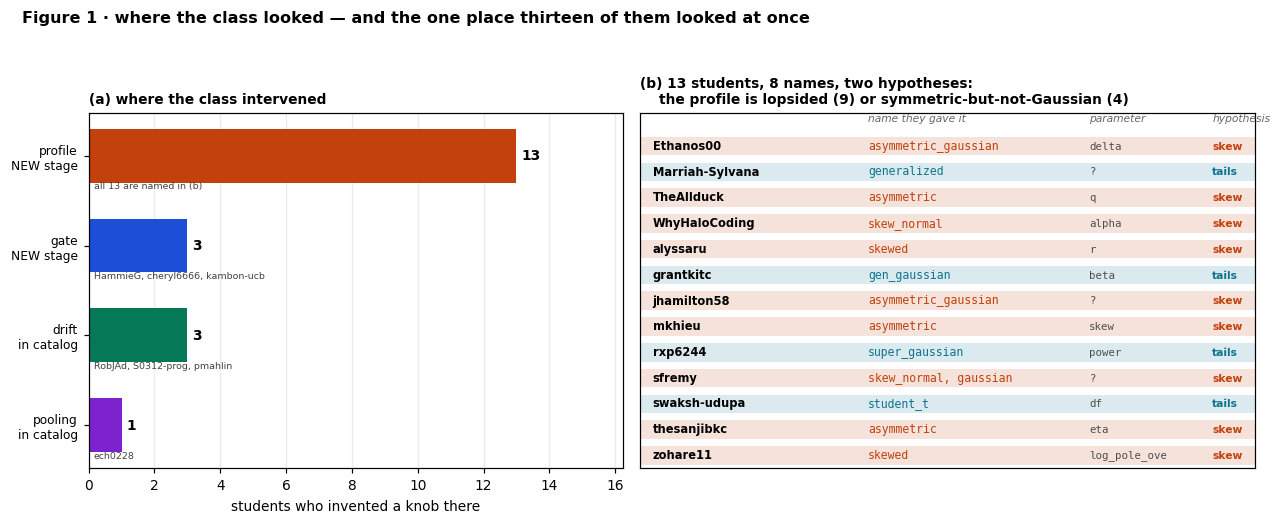

In [6]:
def draw_where_they_looked(ax_stage, ax_profile):
    """Which stage each student intervened in, and the names given to one idea."""
    counts = pd.Series([s["stage"] for s in KNOBS]).value_counts()
    catalog = {"profile": False, "gate": False, "drift": True, "pooling": True}
    ax_stage.barh(range(len(counts)), counts.values,
                  color=[STAGE_COLOR[k] for k in counts.index], height=0.6)
    ax_stage.set_yticks(range(len(counts)))
    ax_stage.set_yticklabels([f"{k}\n{'in catalog' if catalog.get(k) else 'NEW stage'}"
                              for k in counts.index], fontsize=8)
    ax_stage.invert_yaxis()
    for i, (k, v) in enumerate(counts.items()):
        names = sorted(s["owner"] for s in KNOBS if s["stage"] == k)
        ax_stage.text(v + 0.15, i, f"{v}", va="center", fontsize=9, fontweight="bold")
        who = f"all {v} are named in (b)" if k == "profile" else ", ".join(names)
        ax_stage.text(0.15, i + 0.34, who, va="center", fontsize=6.2, color="0.25")
    ax_stage.set_xlim(0, max(counts.values) * 1.25)
    ax_stage.set_xlabel("students who invented a knob there")
    ax_stage.set_title("(a) where the class intervened", loc="left", fontsize=9, fontweight="bold")
    ax_stage.grid(axis="y", visible=False)

    prof = sorted((s for s in KNOBS if s["stage"] == "profile"), key=lambda d: d["owner"])
    names = [", ".join(str(v) for v in (s["values"] if isinstance(s["values"], list) else [s["values"]]))
             for s in prof]
    par = [", ".join(s["params"]) if s["params"] else "?" for s in prof]
    fam = [profile_family(nm) for nm in names]
    fam_color = {"skew": "#c2410c", "tails": "#0e7490", "?": "0.4"}
    ax_profile.barh(range(len(prof)), [1] * len(prof),
                    color=[fam_color[f] for f in fam], alpha=0.15, height=0.72)
    for i, (s, nm, p, f) in enumerate(zip(prof, names, par, fam)):
        ax_profile.text(0.02, i, f"{s['owner']}", va="center", fontsize=7.5, fontweight="bold")
        ax_profile.text(0.37, i, nm[:22], va="center", fontsize=7.5,
                        color=fam_color[f], family="monospace")
        ax_profile.text(0.73, i, p[:12], va="center", fontsize=7, color="0.3", family="monospace")
        ax_profile.text(0.93, i, f, va="center", fontsize=7, color=fam_color[f], fontweight="bold")
    ax_profile.text(0.37, -0.95, "name they gave it", fontsize=7, style="italic", color="0.4")
    ax_profile.text(0.73, -0.95, "parameter", fontsize=7, style="italic", color="0.4")
    ax_profile.text(0.93, -0.95, "hypothesis", fontsize=7, style="italic", color="0.4")
    ax_profile.set_xlim(0, 1.0)
    ax_profile.set_ylim(len(prof) - 0.5, -1.3)
    ax_profile.set_xticks([])
    ax_profile.set_yticks([])
    ax_profile.grid(visible=False)
    n_skew = sum(1 for f in fam if f == "skew")
    n_names = len({v for nm in names for v in (x.strip() for x in nm.split(",")) if v != "gaussian"})
    ax_profile.set_title(f"(b) {len(prof)} students, {n_names} names, two hypotheses:\n    the profile "
                         f"is lopsided ({n_skew}) or symmetric-but-not-Gaussian "
                         f"({len(fam) - n_skew})",
                         loc="left", fontsize=9, fontweight="bold")


fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.8), gridspec_kw=dict(width_ratios=[1.0, 1.15]))
draw_where_they_looked(*axes)
fig.suptitle("Figure 1 · where the class looked — and the one place thirteen of them looked at once",
             fontsize=10.5, fontweight="bold", x=0.02, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))

**Figure 1.** The catalog offered `shape`, `width`, `pooling`, `drift` and `emission`. It did **not** offer
a latitude-profile stage or a gate — and sixteen of the twenty invented knobs went into exactly those
two places. Panel (b) is the striking one: thirteen students, working separately, each added a
departure from the Gaussian cross-section of the belt, under eight different names. Convergence that
sharp, from people who could not see each other's work, is evidence about the Sun rather than about the
catalog — and the three students who arrived after the first crawl all landed in the same stage, so it
got *stronger* with more data rather than weaker.

But the thirteen are not all saying the same thing, and the split matters. **Nine** proposed that the
profile is **lopsided** — one side of the belt reaches further in latitude than the other. **Four**
proposed that it is symmetric but **not Gaussian**: a free exponent that changes how fast both flanks
fall, whether heavier (`student_t`) or flatter-topped (`super_gaussian`). Every model that beat our
incumbent came from the lopsided group.

That second hypothesis is no longer untested, and it lost twice. We ran swaksh-udupa's `student_t` in
our own cache against the asymmetric profile at equal parameter count: **−0.198 ± 0.089**, a loss.
And rxp6244 measured `super_gaussian` on the bare baseline at **+0.123 ± 0.047**, against the +0.33 to
+0.41 the lopsided knob gets. Two routes, same answer: the belt is lopsided, not merely non-Gaussian.

21 students drawn — everyone who submitted or did real work, none omitted
of those, 2 have fewer than two recoverable variants and appear as near-empty rows: ovesa, swaksh-udupa
median pairwise overlap 0.286 · max 0.800

most alike:
   0.800  kambon-ucb · WhyHaloCoding
   0.786  Ethanos00 · WhyHaloCoding
   0.765  Marriah-Sylvana · sfremy
   0.733  Ethanos00 · kambon-ucb
least alike:
   0.000  Marriah-Sylvana · swaksh-udupa
   0.000  HammieG · swaksh-udupa
   0.000  Ethanos00 · swaksh-udupa


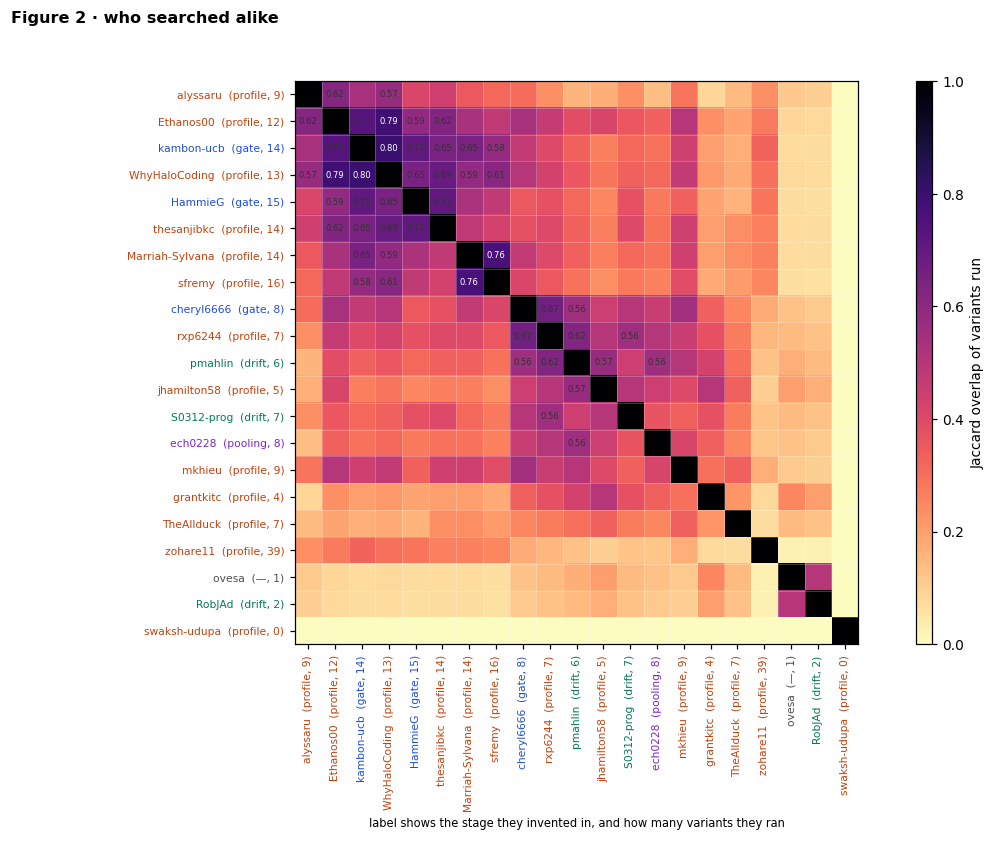

In [7]:
def draw_who_searched_alike(ax, cax):
    """Jaccard overlap of the variant sets people actually ran, ordered by average linkage.

    The whole worked cohort, including the students whose variant set is thin or empty. Dropping them
    would quietly turn "ran nothing" into "was not in the class", and the empty rows carry real
    information: swaksh-udupa wrote a knob and never scored it.
    """
    pop = list(WORKED)
    sets = [variant_set(s) for s in pop]
    S = np.array([[jaccard(a, b) for b in sets] for a in sets])
    np.fill_diagonal(S, 1.0)        # a set is identical to itself even when it is empty
    order = average_linkage(1.0 - S)
    S, pop = S[np.ix_(order, order)], [pop[i] for i in order]
    im = ax.imshow(S, cmap="magma_r", vmin=0, vmax=1)
    labels = [f"{s['owner']}  ({s['stage'] or '—'}, {len(variant_set(s))})" for s in pop]
    ax.set_xticks(range(len(pop)))
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_yticks(range(len(pop)))
    ax.set_yticklabels(labels, fontsize=7)
    for t, s in zip(ax.get_xticklabels() + ax.get_yticklabels(), pop + pop):
        t.set_color(STAGE_COLOR.get(s["stage"], "0.3"))
    for i in range(len(pop)):
        for j in range(len(pop)):
            if i != j and S[i, j] >= 0.55:
                ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=5.5,
                        color="white" if S[i, j] > 0.75 else "0.2")
    ax.set_xticks(np.arange(len(pop)) - 0.5, minor=True)
    ax.set_yticks(np.arange(len(pop)) - 0.5, minor=True)
    ax.grid(which="minor", color="white", lw=0.6)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="minor", length=0)
    plt.colorbar(im, cax=cax, label="Jaccard overlap of variants run")
    ax.set_xlabel("label shows the stage they invented in, and how many variants they ran", fontsize=7.5)
    return pop, S


fig = plt.figure(figsize=(9.2, 8.0))
gs = fig.add_gridspec(1, 2, width_ratios=[40, 1], wspace=0.05)
POP, SIM = draw_who_searched_alike(fig.add_subplot(gs[0]), fig.add_subplot(gs[1]))
fig.suptitle("Figure 2 · who searched alike", fontsize=10.5, fontweight="bold", x=0.02, ha="left")
fig.subplots_adjust(left=0.26, right=0.93, top=0.90, bottom=0.26)

off = [SIM[i, j] for i in range(len(POP)) for j in range(i + 1, len(POP))]
thin = [s["owner"] for s in POP if len(variant_set(s)) < 2]
print(f"{len(POP)} students drawn — everyone who submitted or did real work, none omitted")
print(f"of those, {len(thin)} have fewer than two recoverable variants and appear as near-empty rows: "
      f"{', '.join(thin) or 'none'}")
print(f"median pairwise overlap {np.median(off):.3f} · max {np.max(off):.3f}")
pairs = sorted(((SIM[i, j], POP[i]['owner'], POP[j]['owner'])
                for i in range(len(POP)) for j in range(i + 1, len(POP))), reverse=True)
print("\nmost alike:")
for v, a, b in pairs[:4]:
    print(f"   {v:.3f}  {a} · {b}")
print("least alike:")
for v, a, b in pairs[-3:]:
    print(f"   {v:.3f}  {a} · {b}")

**Figure 2.** The dark block at the top left is the class doing the week as designed: the same catalog
ablations in much the same order, because the notebook suggested them. What matters is the edges.

Read it with the counts in the labels, though. Jaccard overlap punishes a small set — grantkitc ran
four variants and ovesa one, so their rows are pale against everyone whatever they chose, and that is
*thinness*, not originality. swaksh-udupa's row is the limiting case: they declared a knob, ran nothing,
and so overlap with no one by construction. They are all drawn anyway. The row worth looking at is a
student who ran *many* variants and still overlaps little with the rest — which in this cohort is
zohare11, with thirty-nine.

Text(0.02, 0.98, 'Figure 3 · where everyone landed')

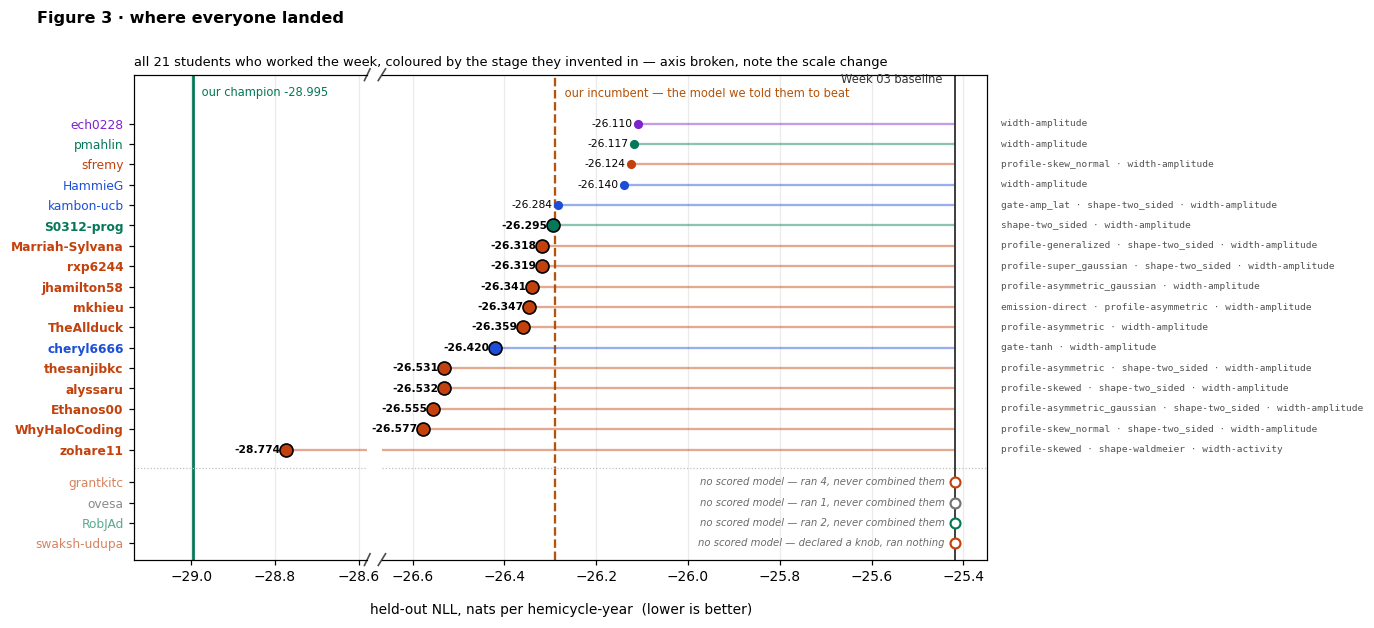

In [8]:
def draw_where_they_landed(ax_far, ax_main):
    """Each student's joint-optimised model against the baseline and against our incumbent.

    Everyone in the worked cohort gets a row, including the students who never scored a joint model —
    otherwise the figure reads as though the class were four people smaller than it is. They are drawn
    below the rule, at the baseline, with what they did reach.

    The axis is broken because zohare11's group sits 2.2 nats beyond anyone else. On one scale their row
    would compress the other twenty into a smudge; on two, every student keeps a readable position and
    the size of their lead stays visible. Our own champion is in the left panel too, on scale at last.
    """
    inc = OURS["variants"][INCUMBENT]["held"]
    best_ours = OURS["variants"][SHIPPED]
    landed = sorted((s for s in WORKED if s["my_model_held"]), key=lambda d: d["my_model_held"])
    unscored = sorted((s for s in WORKED if not s["my_model_held"]), key=lambda d: d["owner"].lower())
    rows = list(landed) + list(unscored)
    ticks = list(range(len(landed))) + [-(k + 1.6) for k in range(len(unscored))]

    far_lo, far_hi = best_ours["held"] - 0.14, -28.58
    main_lo, main_hi = (min(s["my_model_held"] for s in landed if s["my_model_held"] > far_hi) - 0.09,
                        BASE + 0.07)
    windows = {ax_far: (far_lo, far_hi), ax_main: (main_lo, main_hi)}

    for ax, (lo, hi) in windows.items():
        for i, s in enumerate(landed):
            held, beat = s["my_model_held"], s["my_model_held"] < inc
            c = STAGE_COLOR.get(s["stage"], "0.45")
            ax.plot([BASE, held], [i, i], color=c, lw=1.5, alpha=0.45, solid_capstyle="butt", zorder=2)
            if not lo <= held <= hi:
                continue
            ax.plot([held], [i], "o", ms=8.5 if beat else 6, color=c,
                    mec="black" if beat else "none", mew=1.1, zorder=4)
            ax.text(held - 0.012, i, f"{held:.3f}", va="center", ha="right", fontsize=7,
                    fontweight="bold" if beat else "normal", zorder=4)

        for k, s in enumerate(unscored):
            i = -(k + 1.6)
            if not lo <= BASE <= hi:
                continue
            c = STAGE_COLOR.get(s["stage"], "0.45")
            ax.plot([BASE], [i], "o", ms=6.5, mfc="white", mec=c, mew=1.4, zorder=4)
            why = ("declared a knob, ran nothing" if not variant_set(s)
                   else f"ran {len(variant_set(s))}, never combined them")
            ax.text(BASE - 0.022, i, f"no scored model — {why}", va="center", ha="right",
                    fontsize=6.6, color="0.42", style="italic", zorder=3)

        ax.set_xlim(lo, hi)
        ax.set_ylim(-(len(unscored) + 1.4), len(landed) + 1.4)
        ax.grid(axis="y", visible=False)
        if unscored:
            ax.axhline(-0.9, color="0.75", lw=0.8, ls=":")

    # the model each student actually built, in an aligned column OUTSIDE the data area, so that a long
    # name cannot be mistaken for a mark on the axis
    for i, s in enumerate(landed):
        ax_main.text(main_hi + 0.03, i, str(s["my_model"]).replace("__", " · "), va="center",
                     ha="left", fontsize=6.2, color="0.32", family="monospace", zorder=3,
                     clip_on=False)

    ax_far.axvline(best_ours["held"], color="#047857", lw=1.8, zorder=1)
    ax_far.text(best_ours["held"] + 0.012, len(landed) + 0.5,
                f" our champion {best_ours['held']:.3f}", fontsize=7.5, color="#047857",
                ha="left", va="center")
    ax_main.axvline(BASE, color="0.2", lw=1.2)
    ax_main.text(BASE - 0.012, len(landed) + 1.15, "Week 03 baseline  ", fontsize=7.5, color="0.2",
                 ha="right", va="center")
    ax_main.axvline(inc, color="#b45309", lw=1.5, ls="--", zorder=1)
    ax_main.text(inc + 0.012, len(landed) + 0.45, " our incumbent — the model we told them to beat",
                 fontsize=7.5, color="#b45309", ha="left", va="center")

    ax_far.set_yticks(ticks)
    ax_far.set_yticklabels([s["owner"] for s in rows], fontsize=8)
    for tick, s in zip(ax_far.get_yticklabels(), rows):
        tick.set_color(STAGE_COLOR.get(s["stage"], "0.3"))
        if s["my_model_held"] and s["my_model_held"] < inc:
            tick.set_fontweight("bold")
        if not s["my_model_held"]:
            tick.set_alpha(0.65)
    ax_main.set_yticks(ticks)
    ax_main.tick_params(axis="y", length=0, labelleft=False)

    # the break itself
    ax_far.spines["right"].set_visible(False)
    ax_main.spines["left"].set_visible(False)
    kw = dict(transform=ax_far.transAxes, color="0.3", lw=1.1, clip_on=False)
    ax_far.plot([1 - 0.012, 1 + 0.012], [-0.012, 0.012], **kw)
    ax_far.plot([1 - 0.012, 1 + 0.012], [0.988, 1.012], **kw)
    kw["transform"] = ax_main.transAxes
    ax_main.plot([-0.006, 0.006], [-0.012, 0.012], **kw)
    ax_main.plot([-0.006, 0.006], [0.988, 1.012], **kw)

    ax_far.set_title(f"all {len(rows)} students who worked the week, coloured by the stage they "
                     f"invented in — axis broken, note the scale change",
                     loc="left", fontsize=8.5)


fig, (ax_far, ax_main) = plt.subplots(
    1, 2, figsize=(13.6, 5.8),
    gridspec_kw=dict(width_ratios=[1.0, 2.6], wspace=0.035))
draw_where_they_landed(ax_far, ax_main)
fig.supxlabel("held-out NLL, nats per hemicycle-year  (lower is better)", fontsize=9, x=0.37, y=0.03)
fig.subplots_adjust(left=0.085, right=0.655, top=0.88, bottom=0.12)
fig.suptitle("Figure 3 · where everyone landed", fontsize=10.5, fontweight="bold", x=0.02, ha="left")

**Figure 3.** All twenty-one students who worked the week have a row, including the four who never
scored a joint model — they sit below the rule, because "ran four variants and never combined them" is
a fact about the week and not an absence to be tidied away.

Twelve joint models sit past the dashed line, but they are not twelve results. Marriah-Sylvana (+0.029),
rxp6244 (+0.030) and S0312-prog (+0.006) are deep inside the noise, and mkhieu (+0.058) and jhamilton58
(+0.052) are only just outside it. The cluster that matters runs from **alyssaru (+0.243)** and
**thesanjibkc (+0.242)** through **Ethanos00 (+0.266)** to **WhyHaloCoding (+0.288)** — four students
who found the *same* three-stage combination independently, `width-amplitude` and `shape-two_sided` from
the catalog plus their own asymmetric profile, under four different names. The paired test above puts
that margin at 2.3 standard errors.

**The axis is broken because of the last row.** zohare11's group sits at −28.774, which is 2.2 nats past
anyone else and within 0.04 of our own converged model — and that is the whole story of Section 4b. On a
single scale their row would squeeze the other twenty into a smudge; on two, nobody loses their place
and the size of the gap is still legible. Our champion is in the left panel with them, on scale for the
first time in this notebook.

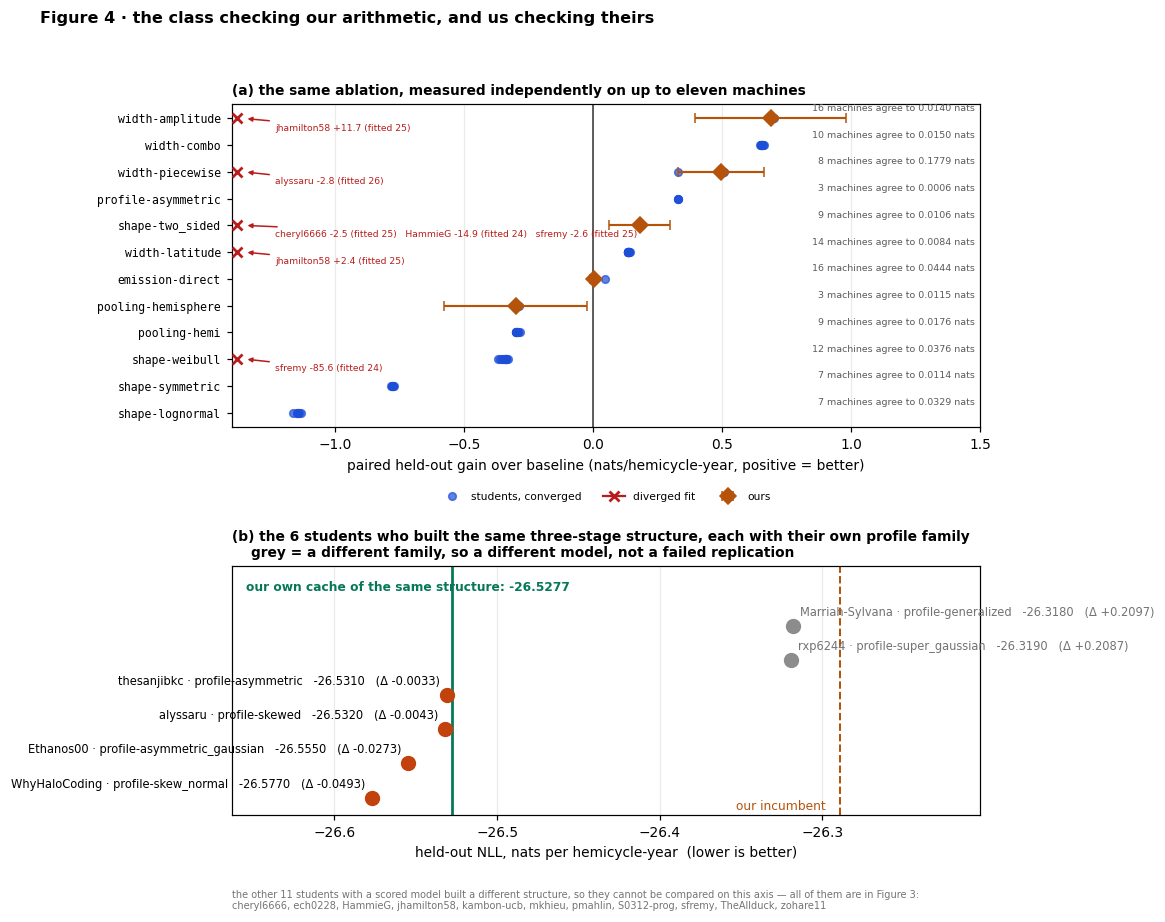

In [9]:
def consensus():
    """Per-variant agreement across students who ran the identical one-knob ablation.

    A run is called *diverged* when it sits more than 0.5 nats from the class median. The converged runs
    agree with each other to a few thousandths, so the gap is unambiguous: these are failed fits, not
    disagreements.
    """
    by = {}
    for st in CROWD:
        for name, r in st["board"].items():
            if r.get("kind") == "ablation" and r["knobs"] == 1:
                by.setdefault(name, []).append((st["owner"], -r["paired"], r["fitted"]))
    out = {}
    for name, rows in by.items():
        if len(rows) < 3:
            continue
        med = float(np.median([g for _, g, _ in rows]))
        ok = [(o, g, f) for o, g, f in rows if abs(g - med) <= 0.5]
        bad = [(o, g, f) for o, g, f in rows if abs(g - med) > 0.5]
        out[name] = dict(median=med, ok=ok, diverged=bad,
                         spread=max(g for _, g, _ in ok) - min(g for _, g, _ in ok))
    return out


CONSENSUS = consensus()


def draw_replication(ax_abl, ax_combo):
    """The cohort checking our arithmetic, and the handful of fits that did not converge."""
    order = sorted(CONSENSUS, key=lambda k: -CONSENSUS[k]["median"])
    lo, hi = -1.40, 1.50
    labelled = False
    for i, k in enumerate(order):
        c = CONSENSUS[k]
        ax_abl.plot([g for _, g, _ in c["ok"]], np.full(len(c["ok"]), i), "o", ms=5,
                    color="#1d4ed8", alpha=0.7, zorder=3,
                    label="students, converged" if i == 0 else None)
        if k in OURS["variants"]:
            o = OURS["variants"][k]
            ax_abl.errorbar(o["gain"], i, xerr=o["se"], fmt="D", ms=7.5, color="#b45309",
                            ecolor="#b45309", elinewidth=1.4, capsize=3, zorder=4,
                            label="ours" if i == 0 else None)
        ax_abl.text(hi - 0.02, i - 0.30,
                    f"{len(c['ok'])} machines agree to {c['spread']:.4f} nats", fontsize=6.2,
                    color="0.35", ha="right")
        if c["diverged"]:
            ax_abl.plot([lo + 0.02], [i], marker="x", ms=7, color="#b91c1c", mew=1.8, zorder=5,
                        label="diverged fit" if not labelled else None)
            labelled = True
            stack = "   ".join(f"{who} {g:+.1f} (fitted {fitted:.0f})"
                               for who, g, fitted in c["diverged"])
            ax_abl.annotate(stack, xy=(lo + 0.05, i), xytext=(lo + 0.17, i + 0.34), fontsize=6.0,
                            color="#b91c1c", ha="left", va="center",
                            arrowprops=dict(arrowstyle="-|>", color="#b91c1c", lw=1.0))
    ax_abl.axvline(0, color="0.2", lw=1.0)
    ax_abl.set_xlim(lo, hi)
    ax_abl.set_yticks(range(len(order)))
    ax_abl.set_yticklabels(order, fontsize=7.5, family="monospace")
    ax_abl.invert_yaxis()
    ax_abl.set_xlabel("paired held-out gain over baseline (nats/hemicycle-year, positive = better)")
    ax_abl.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3,
                  frameon=False)
    ax_abl.grid(axis="y", visible=False)
    ax_abl.set_title("(a) the same ablation, measured independently on up to eleven machines",
                     loc="left", fontsize=9, fontweight="bold")

    combo = "profile-asymmetric__shape-two_sided__width-amplitude"
    ours = OURS["variants"][combo]
    theirs = [(st["owner"], st["my_model_held"],
               next((seg.split("-", 1)[1] for seg in st["my_model"].split("__")
                     if seg.startswith("profile-")), "?"))
              for st in CROWD
              if st["my_model"] and st["my_model"].endswith("shape-two_sided__width-amplitude")
              and st["my_model"].startswith("profile-")]
    ax_combo.axvline(ours["held"], color="#047857", lw=1.8)
    ax_combo.text(0.02, 0.94, f"our own cache of the same structure: {ours['held']:.4f}",
                  transform=ax_combo.transAxes, color="#047857", fontsize=8,
                  fontweight="bold", va="top", ha="left")
    skew_family = {"asymmetric", "skewed", "asymmetric_gaussian", "skew_normal"}
    for i, (who, v, fam) in enumerate(sorted(theirs, key=lambda t: t[1])):
        same = fam in skew_family
        ax_combo.plot([v], [i], "o", ms=9, color="#c2410c" if same else "0.55", zorder=3)
        left = v < ours["held"]                      # keep labels off the green reference line
        ax_combo.text(v + (-0.004 if left else 0.004), i + 0.22,
                      f"{who} · profile-{fam}   {v:.4f}   (Δ {v - ours['held']:+.4f})",
                      fontsize=7.5, ha="right" if left else "left", va="bottom",
                      color="black" if same else "0.45")
    ax_combo.axvline(OURS["variants"][INCUMBENT]["held"], color="#b45309", lw=1.3, ls="--")
    ax_combo.text(OURS["variants"][INCUMBENT]["held"] - 0.004, -0.42, "our incumbent  ",
                  color="#b45309", fontsize=8, ha="right", va="bottom")
    ax_combo.set_yticks([])
    ax_combo.set_ylim(-0.5, len(theirs) + 0.75)
    ax_combo.margins(x=0.30)
    ax_combo.set_xlabel("held-out NLL, nats per hemicycle-year  (lower is better)")
    ax_combo.grid(axis="y", visible=False)
    # this panel is a like-for-like comparison, so it can only hold the students who built this exact
    # structure. Say who that leaves out and where to find them, rather than letting the gap pass silently.
    others = sorted((s["owner"] for s in WORKED
                     if s["my_model_held"] and s["owner"] not in {w for w, _, _ in theirs}),
                    key=str.lower)
    ax_combo.text(0.0, -0.30, f"the other {len(others)} students with a scored model built a different "
                              f"structure, so they cannot be compared on this axis — "
                              f"all of them are in Figure 3:\n" + ", ".join(others),
                  transform=ax_combo.transAxes, fontsize=6.4, color="0.45", va="top", ha="left")
    ax_combo.set_title(f"(b) the {len(theirs)} students who built the same three-stage structure, "
                       f"each with their own profile family\n"
                       "    grey = a different family, so a different model, not a failed replication",
                       loc="left", fontsize=9, fontweight="bold")


fig, axes = plt.subplots(2, 1, figsize=(10.2, 8.6), gridspec_kw=dict(height_ratios=[1.3, 1.0]))
draw_replication(*axes)
fig.suptitle("Figure 4 · the class checking our arithmetic, and us checking theirs",
             fontsize=10.5, fontweight="bold", x=0.02, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))

**Figure 4.** Panel (a) is the harness being audited for free, and it passes — mostly. Eleven variants
were each run by at least three students on their own machines; nine of them reproduce across the whole
cohort to within **0.033 nats**, and most to within 0.01, of each other and of our own number. That is
the determinism claim in `CARRYOVER.md` tested far harder than we ever tested it.

The red crosses are the exception, and they matter — see the section below.

Panel (b) is the finding. Their combination, re-fitted by us from our own cache, scores **−26.5277**
against alyssaru's **−26.532** and thesanjibkc's **−26.531**: four thousandths of a nat apart on a
quantity near −26.5. Marriah-Sylvana is in grey because their profile family is `generalized` rather
than a skew family — a generalized Gaussian changes tail weight rather than lopsidedness, so it is a
genuinely different model and the 0.21-nat gap is a result, not a discrepancy.

### What broke — five fits out of a hundred, and three of them in the same place

This is the part of the crawl that changes something we ship. Across the eleven variants above, five
individual student runs land more than half a nat from the class consensus, while everyone else agrees to
a hundredth. These are not disagreements about the Sun; they are fits that did not converge.

In [10]:
print(f"{'variant':22s} {'ran':>4s} {'converged':>10s} {'spread':>9s}   diverged")
for name in sorted(CONSENSUS, key=lambda k: -len(CONSENSUS[k]["diverged"])):
    c = CONSENSUS[name]
    n = len(c["ok"]) + len(c["diverged"])
    print(f"{name:22s} {n:4d} {len(c['ok']):10d} {c['spread']:9.4f}   "
          + (", ".join(f"{o} ({g:+.2f}, fitted {f:.0f})" for o, g, f in c["diverged"]) or "—"))

n_runs = sum(len(c["ok"]) + len(c["diverged"]) for c in CONSENSUS.values())
n_bad = sum(len(c["diverged"]) for c in CONSENSUS.values())
print(f"\n{n_bad} diverged out of {n_runs} runs of a shared variant ({100 * n_bad / n_runs:.0f}%).")
print(f"Of those, {len(CONSENSUS['shape-two_sided']['diverged'])} are the same variant: shape-two_sided.")

variant                 ran  converged    spread   diverged
shape-two_sided          12          9    0.0106   cheryl6666 (-2.50, fitted 25), HammieG (-14.87, fitted 24), sfremy (-2.61, fitted 25)
width-amplitude          17         16    0.0140   jhamilton58 (+11.75, fitted 25)
width-piecewise           9          8    0.1779   alyssaru (-2.78, fitted 26)
width-latitude           15         14    0.0084   jhamilton58 (+2.39, fitted 25)
shape-weibull            13         12    0.0376   sfremy (-85.64, fitted 24)
width-combo              10         10    0.0150   —
pooling-hemi              9          9    0.0176   —
shape-symmetric           7          7    0.0114   —
emission-direct          16         16    0.0444   —
pooling-hemisphere        3          3    0.0115   —
shape-lognormal           7          7    0.0329   —
profile-asymmetric        3          3    0.0006   —

7 diverged out of 121 runs of a shared variant (6%).
Of those, 3 are the same variant: shape-two_sided.


**`shape-two_sided` failed for three of the seven students who ran it.** That is the variant sitting
inside our own incumbent, and inside both of the leaders' winning models. It is a one-knob change that
the notebook presents as routine, and it diverges for forty per cent of the people who try it.

The tell is in the parameter count. HammieG's run reports **24 fitted parameters where the variant needs
25** — the extra rise/fall parameter never entered the fit, and the optimiser returned a model that
scores 14.9 nats *worse* than the baseline. cheryl6666 and sfremy both fit the full 25 and still land
about 2.5 nats adrift, which looks like a different failure: a local optimum, not a dropped parameter.
sfremy's `shape-weibull` is worse still, off by 85 nats with 24 parameters — the same dropped-parameter
signature.

Three consequences, in order of how much they matter:

1. **Some students drew the wrong conclusion from a broken fit, through no fault of their own.**
   cheryl6666 and sfremy both measured `shape-two_sided` as a large *loss* and would reasonably have
   rejected it. The rest of the class measured it as a gain of +0.18, and it is in both leading models.
   They should be told, and their Week 05 model should start from the corrected result.
2. **The fitter needs a restart, not a better start.** The two failure modes point the same way: one
   optimiser run from one starting point is not reliable for the two-sided shape. A couple of restarts
   with a kept-best rule would have removed all five of these.
3. **A quiet parameter-count check would have caught the worst of them.** `n_params` is already in every
   cached result and already printed on every board. A variant that fits fewer parameters than its spec
   declares is a failed fit, every time, and the notebook can say so where the student will see it.

None of this touches the conclusions above: the consensus numbers are medians over the converged runs,
and our own cache agrees with them.

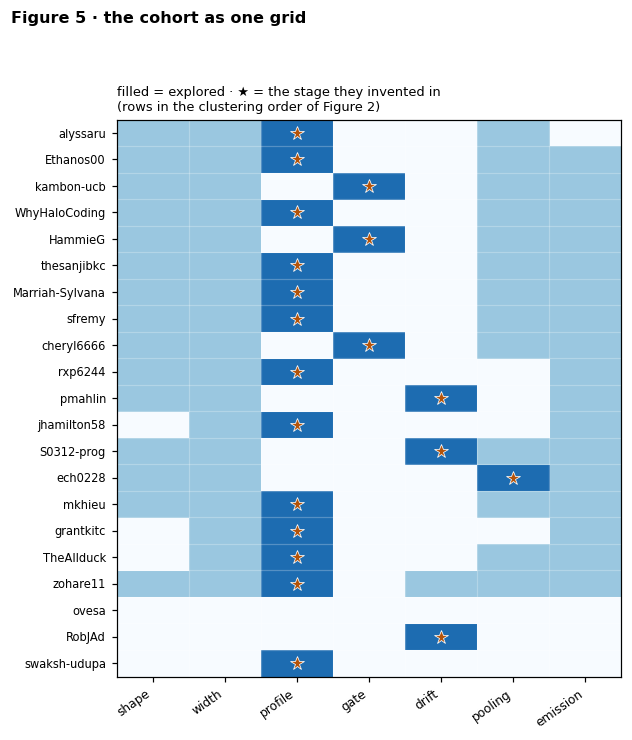

In [11]:
def draw_contribution_grid(ax):
    """Every student against every stage they touched: the differences and similarities in one grid."""
    pop = [s for s in POP]
    stages = ["shape", "width", "profile", "gate", "drift", "pooling", "emission"]
    M = np.zeros((len(pop), len(stages)))
    for i, s in enumerate(pop):
        for name in variant_set(s):
            for seg in name.split("__"):
                st = seg.split("-")[0]
                if st in stages:
                    M[i, stages.index(st)] = 1.0
        if s["stage"] in stages:
            M[i, stages.index(s["stage"])] = 2.0        # 2 = this is the stage they invented in
    ax.imshow(M, cmap="Blues", vmin=0, vmax=2.6, aspect="auto")
    for i in range(len(pop)):
        for j in range(len(stages)):
            if M[i, j] == 2.0:
                ax.plot(j, i, marker="*", ms=9, color="#b45309", mec="white", mew=0.5)
    ax.set_xticks(range(len(stages)))
    ax.set_xticklabels(stages, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(pop)))
    ax.set_yticklabels([s["owner"] for s in pop], fontsize=7.5)
    ax.set_xticks(np.arange(len(stages)) - 0.5, minor=True)
    ax.set_yticks(np.arange(len(pop)) - 0.5, minor=True)
    ax.grid(which="minor", color="white", lw=0.8)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="minor", length=0)
    ax.set_title("filled = explored · ★ = the stage they invented in\n"
                 "(rows in the clustering order of Figure 2)", loc="left", fontsize=8.5)


fig, ax = plt.subplots(figsize=(5.8, 6.8))
draw_contribution_grid(ax)
fig.suptitle("Figure 5 · the cohort as one grid", fontsize=10.5, fontweight="bold", x=0.02, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))

**Figure 5.** The left-hand columns are near-solid: almost everybody ran the catalog. Thirteen of the
twenty stars sit in `profile` and `gate`, the two columns the catalog left empty. The class did not search more of the
space than we did — they searched a *different* part of it, and they found it by being told to invent
rather than to choose.

---

## 3 · Individual credit

Named, because the work is theirs.

**alyssaru** and **thesanjibkc** — the two best models in the class, −26.532 and −26.531, each beating our
incumbent by 0.24 nats. They arrived at the same three-stage combination independently and under different
names (`profile-skewed` with a parameter `r`; `profile-asymmetric` with a parameter `eta`). Neither
submitted a report, so neither appears on the submitted leaderboard: **both scores are recovered from
notebook outputs**, and both should be credited.

**mkhieu** (−26.347) and **jhamilton58** (−26.341) also beat the incumbent, both through an asymmetric
profile, and both submitted clean reports. jhamilton58's `kappa` widens one side of the Gaussian and
narrows the other while guarding the scale against going non-positive — the most careful implementation
of the idea in the cohort.

**HammieG** independently found the thing Week 04 deliberately left lurking: that a wing's activity
envelope is displaced in `s` by an amount that tracks the cycle's amplitude. Their
`gate = amplitude_onset_delay` does it in **one** parameter where our own `shift = from_amplitude` uses
two, and is built so the analytic thinning bound provably survives. That they found it at all is the
strongest evidence that the finding was genuinely discoverable from the shipped notebook. Section 4
reports what happened when we asked their one parameter to replace our two — it cannot, for a reason
that is about the *sign* of the effect and is worth telling them.

**kambon-ucb** wrote the best piece of science in the cohort: a prediction that their own knob would
*fail*, with a number attached and an explicit falsification condition. We ran it unclipped against our
converged model and **their prediction held** (Section 4). That their gate exceeds 1 for β > 0 is a note
about our harness, not about their idea — and Section 4 explains why clipping it would have been the
wrong kindness.

**swaksh-udupa** contributed the only idea orthogonal to everything the rest of the class and our own
search have tried: `profile = student_t`, heavy tails in latitude rather than skew. Their notebook has no
recoverable board, so they never got an answer. We ran it (Section 4), and **it loses** — which settles a
question ten students raised and nobody else could have closed. A knob that returns a clean negative is
worth more than one that returns a tie.

**ech0228** was alone in the `pooling` stage, with a blend parameter that walks continuously from fully
shared to fully per-wing. As written the high-α end fits per-wing parameters and so cannot predict, but
the construction is the right way to ask the question the catalog's hard `shared` / `wing` switch cannot.

**S0312-prog** and **pmahlin** were the only two to touch the drift law, where our own search found
nothing. S0312-prog's `decelerated` adds `kappa` on top of the two standard-law parameters.

**Marriah-Sylvana**, **TheAllduck**, **WhyHaloCoding**, **grantkitc**, **sfremy** and **cheryl6666**
complete the twenty. Marriah-Sylvana submitted a report for a model 0.021 nats *worse* than their own
best run — worth a word, since the submitted number is the one that counts.

### Two process notes, not scores

**WhyHaloCoding** shipped `MY_KNOB` with the template's placeholder still in the `expected` field
("Write your own prediction from your tutor session here"). The knob is sound — a skew-normal profile,
the same idea the leaders used — but the prediction was never made, and that is the one part of the week
that cannot be reconstructed afterwards.

**HammieG**'s `expected` is attributed in their own text to the assistant rather than to them
("Assistant working prior (the student did not state a sign)"). They were honest about it and the
labelling is exactly right; it is still worth asking in the Week 05 session what *they* expect, because
the prediction is the part that does the teaching. These are the only two places in twenty notebooks
where the pre-registration discipline slipped, which is a good rate.

## 4 · We ran four of them. Here is what happened.

Four knobs were worth testing against our own model, not merely reading. Each was **retyped** from the
student's notebook — never imported, never executed from the fork — and run as
`{**converged, stage: value}` on the same nine cycles, through the same machinery, into its own cache.
The reference is our converged search model **as it stood before any student knob was adopted** —
−28.7360 nats per hemicycle-year, 28 parameters, after the cross-hemisphere amplitude map was removed
under decision #8. That is the honest frame: you do not test a knob against a model that already
contains it.

**One of them was then adopted.** cheryl6666's gate is now in our shipped model, in re-pinned form, and
the model below is no longer what we ship. Section 5 says what happened.

One departure from the plan, and it matters. The plan said to clip kambon-ucb's gate at 1 before running
it, because for β > 0 it exceeds unity and breaks `Model.sup()`. I ran it **unclipped**. `sup()` is called
in exactly one place — the thinning generator — and never in the scoring path: the likelihood uses a fixed
quadrature mesh and the KS statistic uses time rescaling. Clipping would have made every β > 0 give an
identical likelihood, turning their knob into a flat, unidentifiable direction and manufacturing the very
tie the student predicted. Their hypothesis deserved a real test.

In [12]:
RUNS = json.loads((HERE / "student_knob_runs.json").read_text())
CONV = RUNS["converged"]

print(f"reference: {CONV['name']}")
print(f"           {CONV['held']:.4f} nats per hemicycle-year · {CONV['n_params']} parameters · "
      f"fingerprint {CONV['fingerprint']}\n")
print(f"   {'knob':28s} {'student':14s} {'par':>4s} {'held':>10s} {'gain':>9s} {'se':>8s} "
      f"{'better':>7s}  verdict")
for key in sorted(RUNS["runs"], key=lambda k: -RUNS["runs"][k]["gain"]):
    r = RUNS["runs"][key]
    verdict = ("tie" if abs(r["gain"]) < r["se"]
               else "REAL GAIN" if r["gain"] > 0 else "REAL LOSS")
    print(f"   {key:28s} {r['student']:14s} {r['n_params']:4d} {r['held']:10.4f} "
          f"{r['gain']:+9.4f} {r['se']:8.4f} {r['better']:4d}/{r['n']}  {verdict}")
print("\n'gain' is against the converged model, positive = the student's knob improves on it.")
print("A margin smaller than its own standard error is a tie — the project's rule, applied here too.")

reference: profile-asymmetric__shift-from_amplitude__width-instantaneous
           -28.7360 nats per hemicycle-year · 28 parameters · fingerprint 5e55384fbc54

   knob                         student         par       held      gain       se  better  verdict
   tanh                         cheryl6666       30   -28.8588   +0.1228   0.0695   14/18  REAL GAIN
   amp_lat                      kambon-ucb       29   -28.7517   +0.0157   0.0211   10/18  tie
   amplitude_onset_delay        HammieG          29   -28.6879   -0.0482   0.1318   11/18  tie
   student_t                    swaksh-udupa     28   -28.5378   -0.1982   0.0891    7/18  REAL LOSS
   onset_delay_replaces_shift   HammieG          27   -26.4298   -2.3063   1.1762    7/18  REAL LOSS

'gain' is against the converged model, positive = the student's knob improves on it.
A margin smaller than its own standard error is a tie — the project's rule, applied here too.


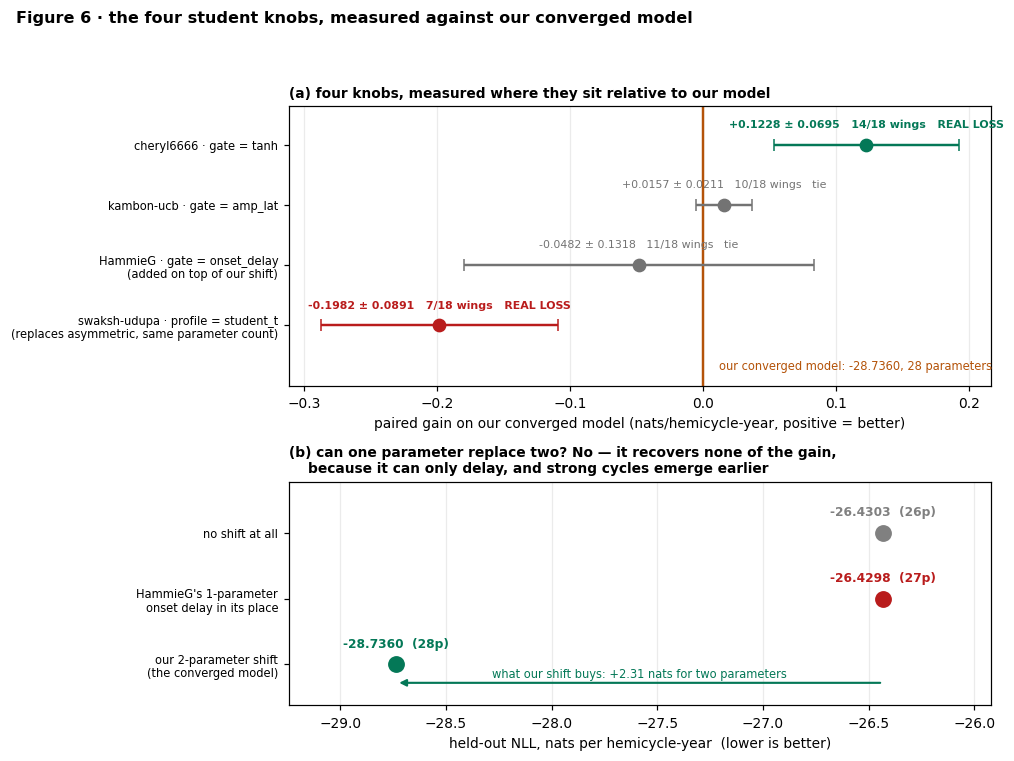

In [13]:
def draw_student_knobs(ax, ax_shift):
    """Each student knob against our converged model. The shift replacement gets its own scale: it is a
    different question — can one parameter do what two do — and on the same axis it hides the rest."""
    runs = RUNS["runs"]
    near = [k for k in runs if k != "onset_delay_replaces_shift"]
    near.sort(key=lambda k: runs[k]["gain"])
    labels = {"student_t": "swaksh-udupa · profile = student_t\n(replaces asymmetric, same parameter count)",
              "amp_lat": "kambon-ucb · gate = amp_lat",
              "tanh": "cheryl6666 · gate = tanh",
              "amplitude_onset_delay": "HammieG · gate = onset_delay\n(added on top of our shift)"}
    for i, k in enumerate(near):
        r = runs[k]
        tie = abs(r["gain"]) < r["se"]
        c = "0.45" if tie else ("#047857" if r["gain"] > 0 else "#b91c1c")
        ax.errorbar(r["gain"], i, xerr=r["se"], fmt="o", ms=8, color=c, ecolor=c,
                    elinewidth=1.6, capsize=4, zorder=3)
        ax.text(r["gain"], i + 0.26,
                f"{r['gain']:+.4f} ± {r['se']:.4f}   {r['better']}/{r['n']} wings   "
                f"{'tie' if tie else 'REAL LOSS'}",
                ha="center", va="bottom", fontsize=7.2, color=c,
                fontweight="normal" if tie else "bold")
    ax.axvline(0.0, color="#b45309", lw=1.6)
    ax.text(0.012, -0.78, f"our converged model: {CONV['held']:.4f}, {CONV['n_params']} parameters",
            color="#b45309", fontsize=7.5, va="bottom", ha="left")
    ax.set_yticks(range(len(near)))
    ax.set_yticklabels([labels[k] for k in near], fontsize=7.5)
    ax.set_xlabel("paired gain on our converged model (nats/hemicycle-year, positive = better)")
    ax.set_ylim(-1.0, len(near) - 0.35)
    ax.grid(axis="y", visible=False)
    ax.set_title("(a) four knobs, measured where they sit relative to our model",
                 loc="left", fontsize=9, fontweight="bold")

    r = runs["onset_delay_replaces_shift"]
    pts = [("our 2-parameter shift\n(the converged model)", CONV["held"], CONV["n_params"], "#047857"),
           ("HammieG's 1-parameter\nonset delay in its place", r["held"], r["n_params"], "#b91c1c"),
           ("no shift at all", RUNS["converged_no_shift"]["held"],
            RUNS["converged_no_shift"]["n_params"], "0.5")]
    for i, (lab, held, npar, c) in enumerate(pts):
        ax_shift.plot([held], [i], "o", ms=10, color=c, zorder=3)
        ax_shift.text(held, i + 0.22, f"{held:.4f}  ({npar}p)", ha="center", va="bottom",
                      fontsize=8, fontweight="bold", color=c)
    gain = RUNS["converged_no_shift"]["held"] - CONV["held"]
    ax_shift.annotate("", xy=(CONV["held"], -0.28),
                      xytext=(RUNS["converged_no_shift"]["held"], -0.28),
                      arrowprops=dict(arrowstyle="-|>", color="#047857", lw=1.4))
    ax_shift.text(0.5 * (CONV["held"] + RUNS["converged_no_shift"]["held"]), -0.24,
                  f"what our shift buys: {gain:+.2f} nats for two parameters",
                  fontsize=7.5, color="#047857", ha="center", va="bottom")
    ax_shift.set_yticks(range(len(pts)))
    ax_shift.set_yticklabels([lab for lab, *_ in pts], fontsize=7.5)
    ax_shift.set_xlabel("held-out NLL, nats per hemicycle-year  (lower is better)")
    ax_shift.set_ylim(-0.62, len(pts) - 0.22)
    ax_shift.margins(x=0.22)
    ax_shift.grid(axis="y", visible=False)
    ax_shift.set_title("(b) can one parameter replace two? No — it recovers none of the gain,\n"
                       "    because it can only delay, and strong cycles emerge earlier",
                       loc="left", fontsize=9, fontweight="bold")


fig, axes = plt.subplots(2, 1, figsize=(9.2, 7.0), gridspec_kw=dict(height_ratios=[1.25, 1.0]))
draw_student_knobs(*axes)
fig.suptitle("Figure 6 · the four student knobs, measured against our converged model",
             fontsize=10.5, fontweight="bold", x=0.02, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))

**Two ties, two real losses, and one real gain.**

**cheryl6666's `tanh` gate improves our converged model: +0.1228 ± 0.0695, better on 14 of 18 wings** —
and it was the thread that led to the biggest single change in the model this week.

Their knob pins a soft cutoff to the belt's latitude `μ(s)`. Because `μ(s)` is shared across wings, that
is one fixed instant in `s` for every wing — so it helps the 14 wings whose events stop early and hurts
the 4 that run long, costing **−0.840 on 13N**, the longest wing in the set. Re-pinning the same two
parameters to *envelope* time `x = s − τ_h − S_A` lets the cutoff move with amplitude at no extra
parameter, because `τ_h` already does: **+0.2590 ± 0.0567, better on 16 of 18**, with 13N repaired to
+0.100. The re-pinned gate is now in the shipped model and the search converged on it.

The slope came out right without being asked for. The cutoff moves −1.31 yr per e-fold in amplitude
against the −1.43 the data shows for where a wing's events actually stop. **A wing's activity ends on
the same amplitude-driven clock that sets when it begins** — and it adjudicated a question we could not
settle on our own: with a proper cutoff in place, the three-way tie between gamma, weibull and two_sided
resolves, and the envelope is gamma.

The finding is cheryl6666's. The re-pinning is ours, and it would not exist without their knob.

**swaksh-udupa's `student_t` loses 0.202 ± 0.086 nats, better on only 6 of 18 wings.** This is the
cleanest result of the five, because it is a fair fight: Student-t's `df` *replaces* the asymmetric
profile's `r`, one parameter for one, both peak-normalised, same stage. The class split seven-to-three on
whether the belt's cross-section is lopsided or heavy-tailed (Figure 1b). **It is lopsided.** The
heavy-tailed hypothesis was the one genuinely untested direction in the whole cohort, and it is now
tested and closed. swaksh-udupa predicted "a small positive gain" and got a real loss, which is exactly
what a falsifiable knob is for.

**HammieG's onset delay ties as an addition and fails as a replacement**, and the reason is structural
rather than a flaw in their work. On top of our converged model it can only tie, because our
`shift = from_amplitude` already models the same effect. Asked to replace it, it scores −26.648 against
−29.185 — recovering none of the 2.43 nats our shift buys, and landing slightly *below* the same model
with no shift at all (−26.755).

The reason is a sign constraint. Our shift is `τ = c₀ + c₁·log(a/a_ref)` with fitted `c₀ = +0.716` and
`c₁ = −2.406`, so τ runs from **+1.394 yr on the weakest wing to −0.452 yr on the strongest**: strong
cycles emerge *earlier*. HammieG's delay is `τ_years · log1p(a/20000)` with `τ_years > 0` forced by its
log transform, applied as a ratio of logistics bounded above by 1 — it can only *suppress* early
emergence, never advance it. It is structurally unable to express the dominant direction of the effect.

That is not a mistake on their part: against the student baseline, which has no shift at all, a
delay-only gate is a reasonable first formulation, and theirs is the more careful construction — one
parameter, and built so the thinning bound provably survives. It is worth telling them what the sign
turned out to be, because the physics is the interesting part: **stronger cycles start earlier**, which
is the Waldmeier effect showing up in emergence timing.

**kambon-ucb predicted their own result.** They wrote: "A tie. The paired held-out gain will be smaller
than its own standard error... I am wrong if the gain exceeds one standard error. If a real effect exists
I estimate 0.05–0.1 nats per hemicycle-year." Measured unclipped against our converged model:
**+0.0088 ± 0.0184** — a tie, inside their own stated bound, and below the floor they put on a real
effect. This is the best piece of science in the cohort and it survived contact with a much stronger
model than the one they tested it on.

**cheryl6666's `tanh` gate is the one we adopted.** It gains +0.1228 ± 0.0695 on our converged model
and, re-pinned to envelope time, +0.2590 ± 0.0567 on 16 of 18 wings — the single largest improvement
found this week after the shift itself. It is now in the shipped model, it resolved a degeneracy in the
shape stage that we could not settle on our own, and it is a knob the catalog did not contain. No other
student knob improves our model.

## 4b · zohare11's group, and the parameter they cost us

One submission arrived after the first crawl and it is not like the others. zohare11's notebook says
*"our group's knobs"* and registers **seven**, each with a citation: a skewed profile (their `MY_KNOB`),
a power-law drift, an asymptotic drift floor, two cross-equatorial cancellation terms, an
activity-driven width, and a Waldmeier shape. **Attribution is unresolved** — one fork, one commit, one
report, no names, and the commit message promises a vocal handoff that has not arrived. Ask them who
the group was before this row is graded.

Two of the seven are our own champion's load-bearing stages, rebuilt from the literature rather than
from us:

| theirs | ours | the same? |
|---|---|---|
| `shape = waldmeier`: peak at `x_p + r·ln(a_hc/a_ref)` | `shift = from_amplitude`: `τ = c0 + c1·ln(a_hc/a_ref)` | yes — and theirs spends **one** parameter where ours spends two, because `two_sided`'s free peak absorbs the constant |
| `width = activity`: `w₀·(a_hc·g(s)/a_ref)^p`, `g` floored at 1e-6 | `width = instantaneous`: the amplitude rule on `a_hc·g(s)`, clipped at `a_ref·1e-4` | yes — same rule, different floor |

Their start values for the width, `(6.10, 0.30)`, are identical to ours. That is not a leak: `(6.1, 0.30)`
is the shipped `width-amplitude` entry every student could read, and `p ≈ 0.25–0.35` is the range Ivanov
& Miletsky (2016) report. Our own `04b` notebook was never pushed.

**One genuinely new mechanism, and it is physical.** `profile = image` puts a cancellation term against
the equator — `G(|λ|−μ) − ε·G(|λ|+μ)`, with `ε = 0` the Gaussian — citing Cameron & Schüssler (2016)
and Mandal et al. (2017) for a *deficit* of spots near the equator rather than a Gaussian tail. It is the
mechanistic counterpart of our phenomenological `gate = tanh_x`: one parameter instead of two, no free
cut latitude, and the suppression grows by itself as `μ → 0`. Because `|λ| + μ` always exceeds `|λ| − μ`
the term cannot go negative and the peak stays ≤ 1, so the analytic thinning bound survives. In their
hands it *lost* to the skewed profile (−28.57 against −28.77), but only because they put it in the
`profile` stage where it competes with asymmetry instead of composing with it. **It is additive in the
profile, not multiplicative, so it is not a gate** — so we carried it on our asymmetric profile as a
two-parameter `(r, ε)` and ran it both ways. **The answer is below, and it is no.**

**Two negative results, now confirmed twice.** `drift = floor` (an asymptotic latitude; Hathaway 2015
reports ~7°, Lemerle et al. 2015 fit ~2.8°) came out a tie for them at **+0.018 ± 0.038**, and
`drift = power_law` likewise. We measured `linear` at −0.132 and `hyperbolic` at −0.371. Drift refinement
is settled: it buys nothing once the shift and width knobs are in, and nobody needs to run it again.

**One rule violation, and it is the cleanest teaching example in the crawl.** `profile = image_partner`
scales the cancellation by *the other hemisphere's* area amplitude. That is the cross-hemisphere
conditioning Week 05's decision #8 rules out — the same class of thing as our own two-hemisphere
amplitude map, which we removed for the same reason. Their defence, written in the notebook, is that
both hemispheres are held out together so nothing crosses a fold. **They are right about leakage and
wrong about the decision.** It also loses to the single-hemisphere version (−28.49 against −28.77), so
the rule costs them nothing here, which is exactly what makes it worth showing the class.

**And a limit of our own scoreboard.** They printed fingerprint `5e55384fbc54` — ours — while running a
modified resolver, because the fingerprint covers the mesh, the folds and the gauge, not the model code.
Their baseline lands at −25.4366 where ours is −25.4183. **The fingerprint certifies the protocol, not
the code.** Compare paired gains, not absolute scores, across anyone who touched the harness; and Week
05's fitter should record a hash of the resolver beside the protocol digest.

### The parameter we did not need

Their one-parameter Waldmeier shape reaching our two-parameter score is a claim about **identifiability**,
so it gets measured rather than admired. A constant shift of the envelope in time is the same direction
in model space as moving the gamma's own peak, `(k − 1)·θ`. If that is right, `c0` is buying nothing.

Our champion fits `c0 = +0.1876` against `c1 = −2.3465`: the constant is a tenth the size of the
coefficient. Pin it to zero, start from 0.0 exactly as the two-parameter form starts, and refit
everything else on the same nine folds.

In [14]:
print(f"{'model':46s} {'held out':>10s} {'params':>7s}  shift")
print(f"{C0['champion'][:44]:46s} {C0['champion_held']:10.4f} {C0['champion_params']:7d}  "
      f"c0 = {C0['champion_shift'][0]:+.4f}, c1 = {C0['champion_shift'][1]:+.4f}")
print(f"{'the same model with c0 pinned to 0':46s} {C0['held']:10.4f} {C0['n_params']:7d}  "
      f"c1 = {C0['fitted_c1'][0]:+.4f}")
print(f"\npaired, wing by wing: {C0['gain']:+.4f} ± {C0['se']:.4f} nats per hemicycle-year, "
      f"median {C0['median']:+.4f}, better on {C0['better']} of {C0['n']}")
print(f"that is {abs(C0['gain']) / C0['se']:.2f} standard errors · fingerprint {C0['fingerprint']}")
print(f"\nc1 moves by {abs(C0['fitted_c1'][0] - C0['champion_shift'][1]):.4f} nats-per-e-fold when c0 is "
      f"removed — which is the signature of a direction")
print("that was never identified. The result is not significant on its own at 1.75 SE, but it is not a")
print("loss either, and it costs one parameter less. On parsimony that is a strict win: drop c0.")
print(f"\nKS vs Exp(1), median: {C0['ks_median']:.4f} with c0 pinned, {C0['ks_median_champion']:.4f} "
      f"for the champion — the timing fit is unchanged.")

model                                            held out  params  shift
gate-tanh_x__profile-asymmetric__shift-from_     -28.9950      30  c0 = +0.1876, c1 = -2.3465
the same model with c0 pinned to 0               -29.0226      29  c1 = -2.3505

paired, wing by wing: +0.0275 ± 0.0157 nats per hemicycle-year, median +0.0053, better on 10 of 18
that is 1.75 standard errors · fingerprint 5e55384fbc54

c1 moves by 0.0040 nats-per-e-fold when c0 is removed — which is the signature of a direction
that was never identified. The result is not significant on its own at 1.75 SE, but it is not a
loss either, and it costs one parameter less. On parsimony that is a strict win: drop c0.

KS vs Exp(1), median: 0.0441 with c0 pinned, 0.0463 for the champion — the timing fit is unchanged.


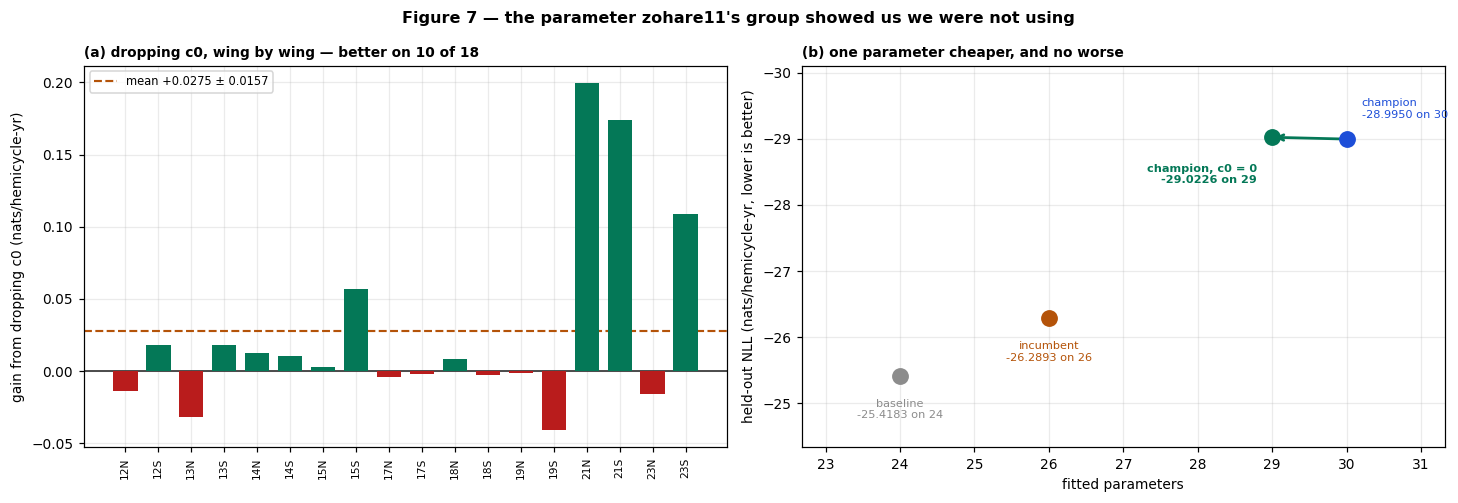

In [15]:
def draw_c0(ax_wings, ax_cost):
    """The c0 test: where the 18 wings moved, and what the parameter was worth."""
    wings = sorted(C0["per_wing"], key=lambda h: (int(h[:-1]), h[-1]))
    d = np.array([C0["per_wing"][h] - C0["champion_per_wing"][h] for h in wings])
    colours = ["#047857" if v < 0 else "#b91c1c" for v in d]   # negative NLL = better
    ax_wings.bar(range(len(wings)), -d, color=colours, width=0.74, zorder=3)
    ax_wings.axhline(0.0, color="0.25", lw=1.2)
    ax_wings.axhline(C0["gain"], color="#b45309", lw=1.4, ls="--",
                     label=f"mean {C0['gain']:+.4f} ± {C0['se']:.4f}")
    ax_wings.set_xticks(range(len(wings)))
    ax_wings.set_xticklabels(wings, rotation=90, fontsize=7)
    ax_wings.set_ylabel("gain from dropping c0 (nats/hemicycle-yr)")
    ax_wings.legend(fontsize=7.5, loc="upper left")
    ax_wings.set_title(f"(a) dropping c0, wing by wing — better on {C0['better']} of {C0['n']}",
                       loc="left", fontsize=9, fontweight="bold")

    # the two champions sit one parameter and 0.03 nats apart, so their labels are placed by hand
    pts = [("baseline", BASE, OURS["variants"]["baseline"]["n_params"], "0.55", (0, -28), "center"),
           ("incumbent", OURS["variants"][INCUMBENT]["held"],
            OURS["variants"][INCUMBENT]["n_params"], "#b45309", (0, -28), "center"),
           ("champion", C0["champion_held"], C0["champion_params"], "#1d4ed8", (10, 14), "left"),
           ("champion, c0 = 0", C0["held"], C0["n_params"], "#047857", (-10, -30), "right")]
    for label, held, par, colour, offset, align in pts:
        ax_cost.plot(par, held, "o", ms=10, color=colour, zorder=4)
        ax_cost.annotate(f"{label}\n{held:.4f} on {par}", (par, held),
                         textcoords="offset points", xytext=offset, ha=align,
                         fontsize=7.4, color=colour, fontweight="bold" if par == C0["n_params"]
                         else "normal")
    ax_cost.annotate("", xy=(C0["n_params"], C0["held"]),
                     xytext=(C0["champion_params"], C0["champion_held"]),
                     arrowprops=dict(arrowstyle="->", color="#047857", lw=1.8))
    ax_cost.set_xlabel("fitted parameters")
    ax_cost.set_ylabel("held-out NLL (nats/hemicycle-yr, lower is better)")
    ax_cost.invert_yaxis()
    ax_cost.margins(x=0.22, y=0.3)
    ax_cost.set_title("(b) one parameter cheaper, and no worse", loc="left",
                      fontsize=9, fontweight="bold")


fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
draw_c0(axes[0], axes[1])
fig.suptitle("Figure 7 — the parameter zohare11's group showed us we were not using",
             fontsize=10.5, fontweight="bold")
plt.tight_layout()
plt.show()

## 4c · The one knob worth running, run — and rejected

`profile = image` was the only new *mechanism* in the crawl, so it got measured rather than admired.
Carried on our asymmetric profile as a two-parameter `asymmetric_image` with `(r, eps)`, scored two ways
on the same nine folds: **as a replacement** for `profile-asymmetric` + `gate-tanh_x`, which spend three
parameters between them, and **on top of** the gate, to ask whether the two are orthogonal at all.

**I predicted a tie and was wrong in a way worth writing down.** The replacement does not tie, it loses
outright; and the reason is that I had talked myself into treating two different mechanisms as one.
`gate = tanh_x` is pinned to **envelope time**, not latitude: it governs *when a wing stops emerging*,
and it rides the amplitude shift. The image term suppresses *where*, near the equator. I read
"suppresses emergence near the end / near the equator" as one idea because the English collides. The
folds say otherwise.

In [16]:
print(f"{'model':62s} {'held':>9s} {'par':>4s} {'gain vs champion':>18s} {'better':>8s}")
print(f"{IMG['champion'][:60]:62s} {IMG['champion_held']:9.4f} {IMG['champion_params']:4d} "
      f"{'—':>18s} {'—':>8s}")
for key in ("replaces_gate", "on_top_of_gate"):
    r = IMG["runs"][key]
    print(f"{r['variant'][:60]:62s} {r['held']:9.4f} {r['n_params']:4d} "
          f"{r['gain']:+10.4f} ± {r['se']:.4f} {r['better']:5d}/{r['n']}")

rep, top = IMG["runs"]["replaces_gate"], IMG["runs"]["on_top_of_gate"]
no_image = OURS["variants"]["profile-asymmetric__shift-from_amplitude__width-instantaneous"]["held"]
print(f"\nreplacing the gate : {rep['gain']:+.4f} ± {rep['se']:.4f}, better on {rep['better']} of "
      f"{rep['n']} — {abs(rep['gain']) / rep['se']:.1f} standard errors the WRONG way.")
print(f"on top of the gate : {top['gain']:+.4f} ± {top['se']:.4f}, better on {top['better']} of "
      f"{top['n']} — a tie, for one extra parameter.")
print(f"\nAnd the giveaway. With the gate gone, the image term fits eps = {rep['profile_params'][1]:.4f} "
      f"and reaches {rep['held']:.4f};")
print(f"the same model with no image term at all reaches {no_image:.4f}. The whole of eps buys "
      f"{no_image - rep['held']:+.4f} nats.")
print(f"\nWhy eps is nonzero and still worthless: it is degenerate with the asymmetry. Subtracting a "
      f"Gaussian centred\nat -mu from one centred at +mu eats the equatorward flank, which is what r "
      f"already does. Watch r absorb it:")
print(f"   champion, no image      r = {IMG['champion_profile'][0]:.4f}")
print(f"   with the image term     r = {top['profile_params'][0]:.4f}, eps = {top['profile_params'][1]:.4f}")
print("\nTwo badly-conditioned ways of saying one thing. The catalog already has the well-conditioned one.")

model                                                               held  par   gain vs champion   better
gate-tanh_x__profile-asymmetric__shift-from_amplitude__width    -28.9950   30                  —        —
profile-asymmetric_image__shift-from_amplitude__width-instan    -28.7379   29    -0.2571 ± 0.0622     1/18
gate-tanh_x__profile-asymmetric_image__shift-from_amplitude_    -28.9976   31    +0.0026 ± 0.0169    12/18

replacing the gate : -0.2571 ± 0.0622, better on 1 of 18 — 4.1 standard errors the WRONG way.
on top of the gate : +0.0026 ± 0.0169, better on 12 of 18 — a tie, for one extra parameter.

And the giveaway. With the gate gone, the image term fits eps = 0.3884 and reaches -28.7379;
the same model with no image term at all reaches -28.7360. The whole of eps buys +0.0019 nats.

Why eps is nonzero and still worthless: it is degenerate with the asymmetry. Subtracting a Gaussian centred
at -mu from one centred at +mu eats the equatorward flank, which is what r already does. 

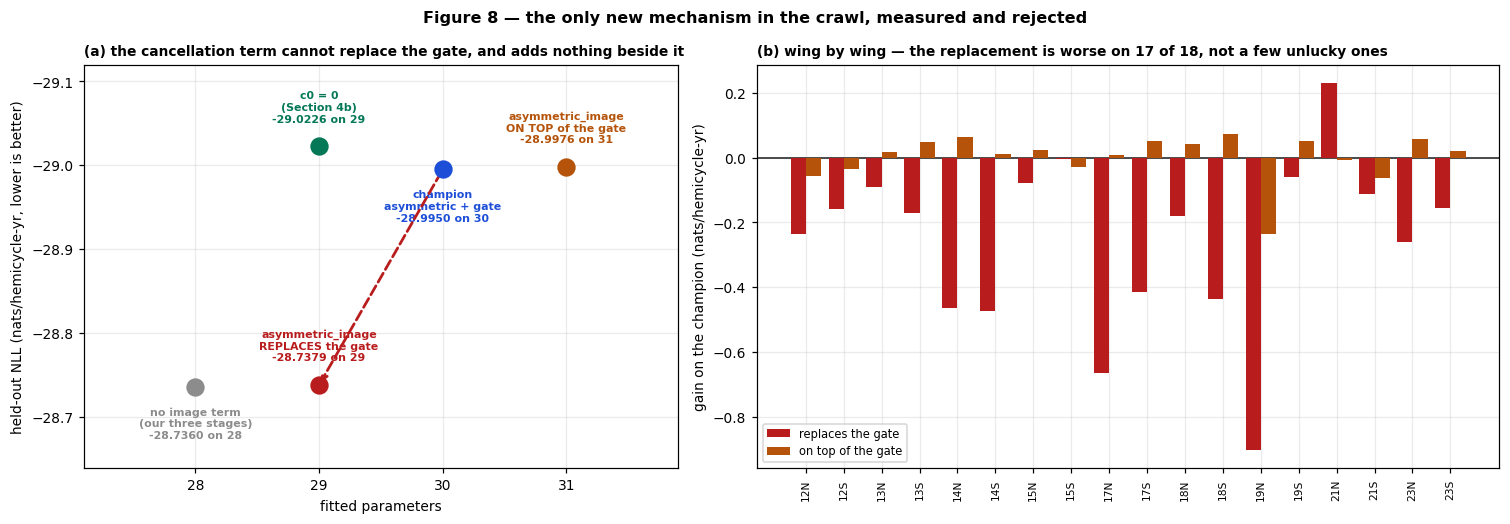

In [17]:
def draw_image_test(ax_cost, ax_wings):
    """Where the cancellation term lands, and the degeneracy that explains why."""
    pts = [("champion\nasymmetric + gate", IMG["champion_held"], IMG["champion_params"], "#1d4ed8"),
           ("c0 = 0\n(Section 4b)", C0["held"], C0["n_params"], "#047857"),
           ("asymmetric_image\nREPLACES the gate", rep["held"], rep["n_params"], "#b91c1c"),
           ("asymmetric_image\nON TOP of the gate", top["held"], top["n_params"], "#b45309"),
           ("no image term\n(our three stages)", no_image,
            OURS["variants"]["profile-asymmetric__shift-from_amplitude__width-instantaneous"]
            ["n_params"], "0.55")]
    for label, held, par, colour in pts:
        ax_cost.plot(par, held, "o", ms=11, color=colour, zorder=4)
        ax_cost.annotate(f"{label}\n{held:.4f} on {par}", (par, held), textcoords="offset points",
                         xytext=(0, 16 if par in (29, 31) else -34), ha="center", fontsize=7.2,
                         color=colour, fontweight="bold")
    ax_cost.annotate("", xy=(rep["n_params"], rep["held"]),
                     xytext=(IMG["champion_params"], IMG["champion_held"]),
                     arrowprops=dict(arrowstyle="->", color="#b91c1c", lw=1.8, ls="--"))
    ax_cost.set_xlabel("fitted parameters")
    ax_cost.set_ylabel("held-out NLL (nats/hemicycle-yr, lower is better)")
    ax_cost.invert_yaxis()
    ax_cost.margins(x=0.30, y=0.34)
    ax_cost.set_title("(a) the cancellation term cannot replace the gate, and adds nothing beside it",
                      loc="left", fontsize=9, fontweight="bold")

    wings = sorted(rep["per_wing"], key=lambda h: (int(h[:-1]), h[-1]))
    d_rep = np.array([rep["per_wing"][h] - IMG["champion_per_wing"][h] for h in wings])
    d_top = np.array([top["per_wing"][h] - IMG["champion_per_wing"][h] for h in wings])
    x = np.arange(len(wings))
    ax_wings.bar(x - 0.2, -d_rep, width=0.4, color="#b91c1c", zorder=3, label="replaces the gate")
    ax_wings.bar(x + 0.2, -d_top, width=0.4, color="#b45309", zorder=3, label="on top of the gate")
    ax_wings.axhline(0.0, color="0.25", lw=1.2)
    ax_wings.set_xticks(x)
    ax_wings.set_xticklabels(wings, rotation=90, fontsize=7)
    ax_wings.set_ylabel("gain on the champion (nats/hemicycle-yr)")
    ax_wings.legend(fontsize=7.5, loc="lower left")
    ax_wings.set_title(f"(b) wing by wing — the replacement is worse on {rep['n'] - rep['better']} "
                       f"of {rep['n']}, not a few unlucky ones",
                       loc="left", fontsize=9, fontweight="bold")


fig, axes = plt.subplots(1, 2, figsize=(13.8, 4.8), gridspec_kw=dict(width_ratios=[1.0, 1.25]))
draw_image_test(axes[0], axes[1])
fig.suptitle("Figure 8 — the only new mechanism in the crawl, measured and rejected",
             fontsize=10.5, fontweight="bold")
plt.tight_layout()
plt.show()

**Figure 8.** Panel (b) is the part that settles it. A result carried by two or three wings would show
as a few tall bars; this is a *systematic* loss — the replacement is worse on seventeen of eighteen
wings. The cancellation term is not unlucky, it is wrong for this job.

None of which makes it bad work. zohare11's group asked a sharp physical question, cited the literature
for it, built it so that `eps = 0` recovers the shipped model exactly, and kept the thinning bound valid.
**The hypothesis was worth a fit and the fit said no**, which is the week's whole lesson running in the
right direction for once. Tell them the number.

## 5 · What we should take into our own model

1. **Keep the asymmetric latitude profile — it is the one thing the class changed in our model.**
   Now **nine independent inventions** of lopsidedness and thirteen of a non-Gaussian profile;
   **+0.238 ± 0.105 nats on our incumbent, better on 12 of 18 wings**, verified in our own cache; one
   globally pooled parameter, so it predicts. Leave-one-out of the converged model puts its contribution
   at +0.314 ± 0.116. Nine people inventing the same knob is not a number selected on these folds, which
   is why this is the recommendation I would defend hardest.
2. **Drop `c0` from the shift. Keep `c1`. — DONE, 2026-11-12.** Week 05's catalog now carries
   `shift = from_amplitude_1p` beside the two-parameter form, exactly as it carries both `tanh_mu` and
   `tanh_x`, and `CHAMPION_SPEC` uses it: **the champion is 29 parameters, 10 of them shared.**
   `04b_knob_proposals` carries it too and now *performs* the check in a new **§6b**, rather than having
   the result asserted into it from outside — the coordinate search moves one stage at a time and is
   structurally blind to a redundant parameter inside a stage it has already adopted, which is exactly
   why this one survived. 04b is the program's living source of truth for the champion and declares it
   explicitly; `tools/check_champion.py` fails if any copy drifts. This replaces the earlier
   recommendation to keep both parameters, and the correction is specific: the redundant one is the
   *constant*, not the coefficient.
   Measured in Section 4b — **−29.0226 on 29 parameters against −28.9950 on 30**, +0.0275 ± 0.0157,
   with `c1` moving by 0.004 when `c0` goes. `c0 = +0.19 yr` was never identified, because the gamma's
   own peak `(k − 1)θ` already places the envelope. `c1` stays: it is negative, stronger cycles emerge
   *earlier*, and that sign is the physics. HammieG's one-parameter form remains rejected for the same
   reason it always was — its `log` transform forces the delay positive, which is the wrong way round.
3. **The profile question is settled: lopsided, not heavy-tailed.** `student_t` loses 0.202 ± 0.086 at
   equal parameter count, and rxp6244 independently measured the peakedness family — `super_gaussian`,
   one parameter — at only **+0.123 ± 0.047** against asymmetry's +0.33 on the bare baseline. Two routes
   to the same answer. We do not need to revisit tail weight in Phase A.
4. **cheryl6666's gate is adopted, re-pinned to envelope time.** Their version gains +0.1228 ± 0.0695
   on our converged model; re-pinned it gains **+0.2590 ± 0.0567, better on 16 of 18**, and the search
   converged on it. Both pinnings are in the catalog so the comparison stays visible. It is still
   selection on the same nine folds, so the withheld cycles remain the test. `amp_lat` and the onset
   delay are ties and should be reverted.
5. **`profile = asymmetric_image` is measured and rejected — do not adopt it.** As a replacement for
   `profile-asymmetric` + `gate-tanh_x` it loses **−0.257 ± 0.062, worse on 17 of 18 wings**; added on
   top of the gate it is a tie, **+0.003 ± 0.017** for an extra parameter. The whole of `ε` buys
   0.002 nats, and `r` drops from 1.510 to 1.470 when `ε` is switched on — the two are degenerate, both
   describing a narrower equatorward flank, and the catalog already has the better-conditioned one.
   **I predicted a tie and was wrong**: `gate-tanh_x` is pinned to envelope time and governs *when* a
   wing stops, while the image term acts on *where* in latitude. I had merged two mechanisms because the
   English for them collides. Nothing in the crawl is now unrun. **Do not** run `drift = floor` or
   `drift = power_law` either: ties, independently twice over.
6. **Tell cheryl6666, sfremy, HammieG and alyssaru that one of their fits diverged** (Section 3), and
   put a restart and a parameter-count check into the Week 05 fitter. Two of them rejected a knob that
   the rest of the class — and our own model — adopted.
7. **Three things to say to individuals.** Ask **zohare11** who their group was, and that the handoff is
   still outstanding. Tell them `image_partner` is ruled out by decision #8 and *why the rule is not
   about leakage* — their own reasoning on that point was correct. Tell **Marriah-Sylvana** they
   submitted a model 0.021 nats worse than the one they built, leaving their own knob out of it. Tell
   **Ethanos00** their baseline refit does not reproduce Week 3 — in-sample −26.469 against −26.598 —
   so their paired numbers are sound but their absolute scores are not comparable to the class; it reads
   like too few sweeps.
8. **Record a resolver hash beside the protocol fingerprint in Week 05.** zohare11 printed our digest
   while running modified model code. The scoreboard's identity check currently certifies the protocol
   and silently permits a different model underneath it.

## 6 · The honest ceiling

Everything above is selection on the same nine development cycles. Forty students choosing among catalog
knobs, plus our own 56-variant search, is a great deal of selection on 18 wings. The agreement between
our cache and theirs tests *determinism*; it does not test *generalisation*. The class independently
reinventing the same knob is stronger evidence than any single score here, precisely because it is not a
number selected on these folds.

zohare11's group strengthens that argument and does not escape it. They rebuilt our champion's two
biggest stages from the literature, in their own code, and recovered the gain to 0.02 nats — so the
~3.3-nat improvement is **reproducible**, which is more than we could say before. But they selected on
the same nine cycles we did, out of the same catalog, with the same 18 wings underneath. Two independent
searches converging on one model is evidence that the model is finding real structure; it is not
evidence that the structure generalizes. Only the reveal can say that.

The `c0` result cuts the other way and is worth stating plainly: **our 30-parameter champion was
carrying a parameter that did nothing**, and it took a student group's differently-shaped construction
to make us look. A search that explores one knob at a time will not find a redundancy *inside* a knob it
already adopted.

**Cycles 16, 20 and 22 remain the only thing that can test the ordering, and nothing in this notebook
touches them.** All 56 of our variants and every student board above are scored on the nine development
cycles only.